# Лабораторная работа №1: регрессия

Датасет: [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) из UCI Machine Learning Repository. По физико-химическим характеристикам вина нужно предсказать его оценку `quality`, которую выставили эксперты (целое число по шкале от 0 до 10).

Красное и белое вино обрабатываю вместе в одной таблице, тип вина кодирую бинарным признаком `is_red`. После анализа данных добавляю новые признаки (логарифмы и полиномиальные признаки) и обучаю **все модели на одном и том же наборе признаков**, чтобы сравнение было честным.

Основная метрика — RMSE, дополнительная — MAE. Порог по заданию: RMSE < 0.70.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set_theme(style="darkgrid")

RANDOM_STATE = 42

# Часть 1. Загружаем данные

Красное и белое вино лежат на UCI в двух отдельных csv-файлах (разделитель `;`). Склеиваю их в одну таблицу и добавляю признак `is_red` (1 — красное, 0 — белое), чтобы модель знала, какого типа вино.

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"
red = pd.read_csv(url + "winequality-red.csv", sep=";")
white = pd.read_csv(url + "winequality-white.csv", sep=";")

red["is_red"] = 1
white["is_red"] = 0

data = pd.concat([red, white], ignore_index=True)
print("Красное:", red.shape, " Белое:", white.shape, " Всего:", data.shape)
data.head()

Красное: (1599, 13)  Белое: (4898, 13)  Всего: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


Пропусков нет, все признаки числовые (11 физико-химических измерений + `is_red`), поэтому заполнять пропуски и кодировать категории не нужно. Целевая переменная `quality` — целое число, но решаем задачу регрессии, т.е. модель предсказывает вещественное число.

Отдельно проверю дубликаты.

In [4]:
features_only = list(data.columns.drop("quality"))

print("Полных дубликатов строк:", data.duplicated().sum())
print("Дубликатов только по признакам (без quality):", data[features_only].duplicated().sum())
print("Групп с одинаковыми признаками, но разной оценкой:", (data.groupby(features_only)["quality"].nunique() > 1).sum())

# насколько далеко друг от друга копии стоят в исходных файлах
for name, df in [("красное", red), ("белое", white)]:
    dups = df[df.duplicated(keep=False)].reset_index()
    span = dups.groupby(list(df.columns))["index"].agg(lambda s: s.max() - s.min())
    print("%s: медианное расстояние между копиями = %d строк, доля копий в пределах 5 строк = %.2f" % (name, span.median(), (span <= 5).mean()))

Полных дубликатов строк: 1177
Дубликатов только по признакам (без quality): 1177
Групп с одинаковыми признаками, но разной оценкой: 0
красное: медианное расстояние между копиями = 2 строк, доля копий в пределах 5 строк = 0.92
белое: медианное расстояние между копиями = 4 строк, доля копий в пределах 5 строк = 0.60


Получается, что примерно 18% строк (1177 из 6497) — точные копии других строк. При этом:
- нет ни одного случая, когда у вин с одинаковыми 11 измерениями разная оценка;
- копии в исходных файлах обычно стоят рядом (у красного в 92% случаев копии находятся в пределах 5 строк друг от друга);
- у признаков десятки и сотни разных значений, так что разным винам случайно совпасть сразу по всем 11 измерениям очень маловероятно.

Скорее всего, это повторные записи одного и того же вина (например, несколько бутылок одной партии), а не разные вина с одинаковыми характеристиками. Но проверить это точно нельзя — в описании датасета на UCI я про это ничего не нашёл.

Удалять их я не стал: это наблюдения из исходного датасета, и скрытая тестовая выборка, скорее всего, тоже содержит такие повторы. Но надо помнить о последствиях: если одна копия попала в train, а другая в test (или в разные фолды кросс-валидации), то для модели это уже «знакомый» объект, и оценка качества получается оптимистичной. Насколько сильно — проверю в анализе ошибок (часть 12).

Если нужен вариант без дубликатов, достаточно раскомментировать строку в ячейке ниже и перезапустить весь ноутбук.

In [5]:
# вариант без дубликатов: раскомментировать строку ниже и перезапустить ноутбук
# data = data.drop_duplicates().reset_index(drop=True)

print(data.shape)

(6497, 13)


# Часть 2. Подготовка выборок

Делю данные на train и test **до** исследовательского анализа. Всё, что я дальше смотрю (распределения, корреляции), смотрю только на train, чтобы выводы и выбор признаков/моделей никак не зависели от ответов тестовой выборки.

In [6]:
from sklearn.model_selection import train_test_split

y = data["quality"]
X = data.drop(columns=["quality"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Доля красного вина в train / test: %.3f / %.3f" % (X_train["is_red"].mean(), X_test["is_red"].mean()))
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).sort_index().round(4)

Train: (5197, 12)  Test: (1300, 12)
Доля красного вина в train / test: 0.249 / 0.235


,train,test
quality,,
3,0.0046,0.0046
4,0.0333,0.0331
5,0.3290,0.3292
6,0.4366,0.4362
7,0.1661,0.1662
8,0.0296,0.0300
9,0.0008,0.0008


**Размер выборок.** Взял 80% / 20%: 5197 объектов в train и 1300 в test. Данных не очень много, поэтому большую часть оставляю на обучение (особенно деревьям важен объём данных), а 1300 объектов в тесте достаточно, чтобы оценка RMSE была стабильной. Подбирать гиперпараметры буду кросс-валидацией внутри train, поэтому отдельная валидационная выборка не нужна.

**Способ разбиения.** Случайное разбиение со стратификацией по `quality`. Оценки сильно несбалансированы: вин с оценкой 3 и 9 единицы (с оценкой 9 всего 5 вин во всём датасете). При обычном случайном разбиении редкие оценки могли бы почти целиком попасть в одну из частей, и тест перестал бы отражать реальное распределение. Стратификация сохраняет доли каждой оценки одинаковыми в train и test (это видно в таблице выше). Доля красного вина тоже получилась примерно одинаковой (0.249 и 0.235). `random_state` зафиксирован, поэтому разбиение воспроизводится.

**Почему нельзя много раз оценивать модели на одной и той же тестовой выборке.** Если подбирать модель, признаки или гиперпараметры, каждый раз проверяя результат на тесте, то тест фактически становится частью обучения: я выберу то, что случайно хорошо сработало именно на этих 1300 объектах. Получится переобучение под тестовую выборку, и оценка на ней станет оптимистичной, т.е. перестанет показывать качество на действительно новых данных. Поэтому все решения я принимаю по кросс-валидации на train, а тест использую только в конце для финального сравнения моделей.

# Часть 3. Знакомство с данными

Весь анализ в этой части — только по обучающей выборке.

quality
3    0.005
4    0.033
5    0.329
6    0.437
7    0.166
8    0.030
9    0.001
Name: proportion, dtype: float64
Среднее = 5.818, медиана = 6.0, std = 0.873
is_red
0    5.883965
1    5.619490
Name: quality, dtype: float64


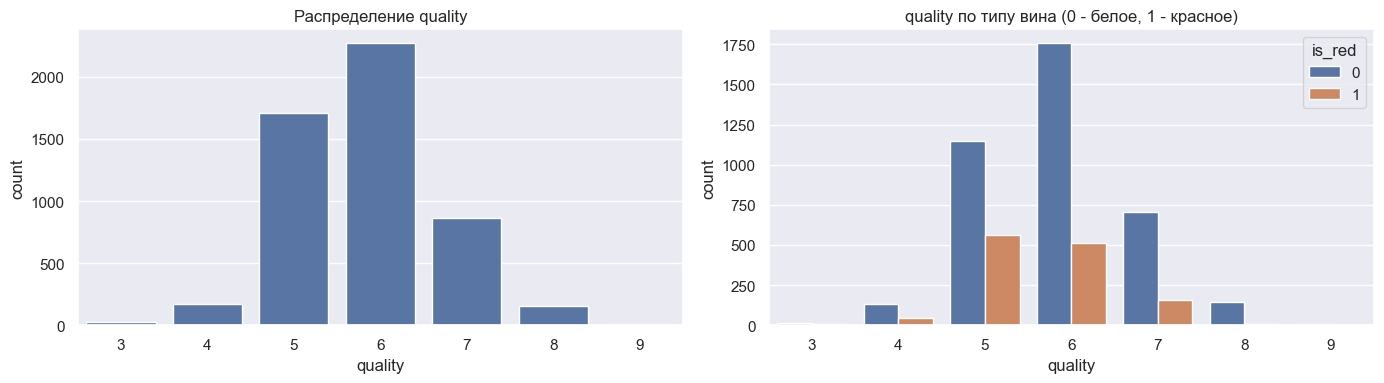

In [7]:
train = X_train.copy()
train["quality"] = y_train

fig, axs = plt.subplots(figsize=(14, 4), ncols=2)
sns.countplot(x=y_train, color="C0", ax=axs[0])
axs[0].set_title("Распределение quality")
sns.countplot(data=train, x="quality", hue="is_red", ax=axs[1])
axs[1].set_title("quality по типу вина (0 - белое, 1 - красное)")
plt.tight_layout()

print(y_train.value_counts(normalize=True).sort_index().round(3))
print("Среднее = %.3f, медиана = %.1f, std = %.3f" % (y_train.mean(), y_train.median(), y_train.std()))
print(train.groupby("is_red")["quality"].mean())

Выводы:
- Оценки сильно сконцентрированы в центре: на 5 и 6 приходится ~77% всех вин, а крайние оценки 3, 4, 8 и 9 вместе — меньше 7% (с оценкой 9 в train всего 4 вина). Значит, даже константа ≈ 5.8 будет в среднем ошибаться меньше чем на балл, а предсказывать крайние оценки моделям будет трудно: примеров мало, и функция потерь (MSE) в основном «тянет» модель к центру.
- Реально используется только шкала 3–9: оценок 0–2 и 10 нет вообще, т.е. совсем плохих и идеальных вин модель никогда не увидит.
- Белых вин в 3 раза больше, чем красных, в среднем они оценены чуть выше (5.88 против 5.62), а оценки 8–9 почти все у белых. Тип вина связан с целевой переменной, поэтому признак `is_red` оставляю.
- `quality` — целое число (порядковая шкала), а регрессия будет выдавать вещественные числа, например 5.6. Для RMSE это нормально: для вина, которое «между» 5 и 6, предсказание 5.6 в среднем даёт меньшую ошибку, чем жёсткий выбор одного из вариантов.

In [8]:
train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5197.0,7.221,1.286,4.200,6.400,7.000,7.700,15.900
volatile acidity,5197.0,0.340,0.166,0.080,0.230,0.290,0.410,1.580
citric acid,5197.0,0.318,0.146,0.000,0.240,0.310,0.390,1.660
residual sugar,5197.0,5.476,4.786,0.600,1.800,3.000,8.100,65.800
chlorides,5197.0,0.056,0.034,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,5197.0,30.548,17.647,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,5197.0,115.964,56.738,6.000,78.000,118.000,156.000,440.000
density,5197.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,5197.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,5197.0,0.532,0.147,0.230,0.430,0.510,0.600,1.950


Выводы:
- Признаки измерены в совершенно разных масштабах: `density` меняется в третьем знаке после запятой (std = 0.003), а `total sulfur dioxide` — от 6 до 440 (std ≈ 57). Для деревьев это неважно, а вот веса линейной регрессии без масштабирования сравнивать между собой будет нельзя (подробнее в части 7).
- У многих признаков длинный правый хвост и выбросы: `residual sugar` (у 75% вин до 8.1, а максимум 65.8), `chlorides`, `free sulfur dioxide` (максимум 289 при 75%-квантиле 41), `sulphates`. Выбросы я не удаляю: это реальные вина, и в тестовой выборке такие тоже могут встретиться. Деревья к выбросам в признаках устойчивы (им важен только порядок значений), а на линейную модель они могут влиять сильнее — к этому вернусь в части 4.

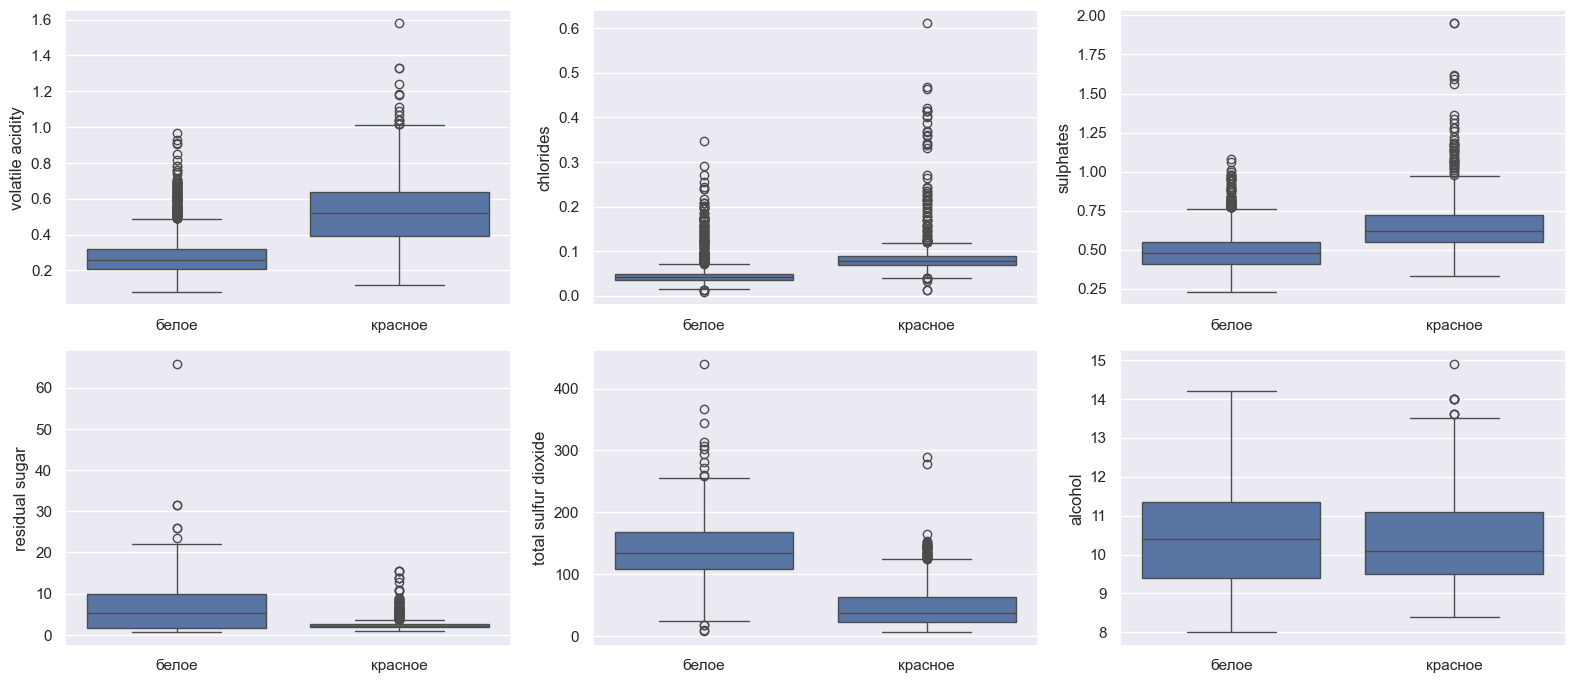

In [9]:
features = ["volatile acidity", "chlorides", "sulphates", "residual sugar", "total sulfur dioxide", "alcohol"]

fig, axs = plt.subplots(figsize=(16, 7), nrows=2, ncols=3)
for i, feature in enumerate(features):
    ax = axs[i // 3, i % 3]
    sns.boxplot(data=train, x="is_red", y=feature, ax=ax)
    ax.set_xticklabels(["белое", "красное"])
    ax.set_xlabel("")
plt.tight_layout()

Выводы: по химическому составу красное и белое вино очень сильно отличаются:
- у белого гораздо больше остаточного сахара и диоксида серы (медиана total sulfur dioxide ~135 у белого и ~40 у красного);
- у красного выше летучая кислотность, хлориды и сульфаты;
- по алкоголю они почти не отличаются.

Значит, одно и то же значение признака может значить разное для разных типов: например, total sulfur dioxide = 150 — обычное значение для белого и очень большое для красного. Поэтому признак `is_red` нужен обязательно. Линейная модель с одним общим весом на признак такие различия учесть не может (через `is_red` она может только сдвинуть предсказание на константу), а деревья могут построить разные правила для разных типов вина.

Посмотрим, какие признаки сильнее всего линейно связаны с `quality` (корреляция Пирсона). Сразу посчитаю её отдельно для белого и красного вина.

Text(0.5, 0, 'Корреляция Пирсона')

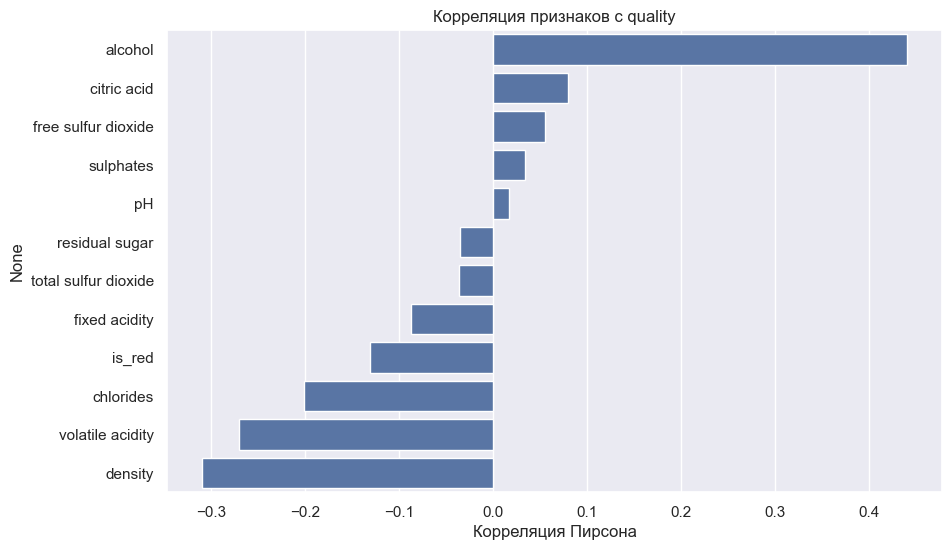

In [10]:
correlations = X_train.corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations, color="C0")
plot.figure.set_size_inches(10, 6)
plt.title("Корреляция признаков с quality")
plt.xlabel("Корреляция Пирсона")

In [11]:
is_red_train = X_train["is_red"] == 1

corr_by_type = pd.DataFrame({
    "все": X_train.drop(columns=["is_red"]).corrwith(y_train),
    "белое": X_train[~is_red_train].drop(columns=["is_red"]).corrwith(y_train[~is_red_train]),
    "красное": X_train[is_red_train].drop(columns=["is_red"]).corrwith(y_train[is_red_train]),
}).sort_values("все")
corr_by_type.round(3)

,все,белое,красное
density,-0.309,-0.304,-0.183
volatile acidity,-0.270,-0.200,-0.372
chlorides,-0.201,-0.207,-0.115
fixed acidity,-0.087,-0.117,0.114
total sulfur dioxide,-0.036,-0.182,-0.180
residual sugar,-0.035,-0.099,-0.001
pH,0.017,0.104,-0.057
sulphates,0.034,0.055,0.257
free sulfur dioxide,0.055,-0.003,-0.035
citric acid,0.080,-0.014,0.210


Выводы:
- Сильнее всего с качеством связан алкоголь (r ≈ 0.44): чем крепче вино, тем выше оценка. Это главный кандидат в признаки.
- Отрицательная связь у `density` (−0.31), `volatile acidity` (−0.27) и `chlorides` (−0.20). Летучая кислотность — это в основном уксусная кислота, при большом её количестве у вина появляется уксусный привкус, так что связь логичная.
- Остальные признаки по отдельности почти не связаны с `quality` (|r| < 0.1). Это ещё не значит, что они бесполезны: корреляция Пирсона ловит только линейную связь и только одного признака.
- Все корреляции умеренные: ни один признак сам по себе качество не определяет, поэтому сильно лучше константы одной линейной зависимостью не получится.
- Для красного и белого вина связи разные. У красного намного важнее летучая кислотность (−0.37 против −0.20), сульфаты (0.26 против 0.06) и лимонная кислота (0.21 против −0.01), у белого — плотность (−0.30 против −0.18) и хлориды. У `fixed acidity` и `pH` знак корреляции у двух типов вообще разный. В объединённом датасете эти эффекты частично смешиваются, и это ещё один аргумент за модели, которые умеют учитывать взаимодействие признаков с типом вина (деревья).

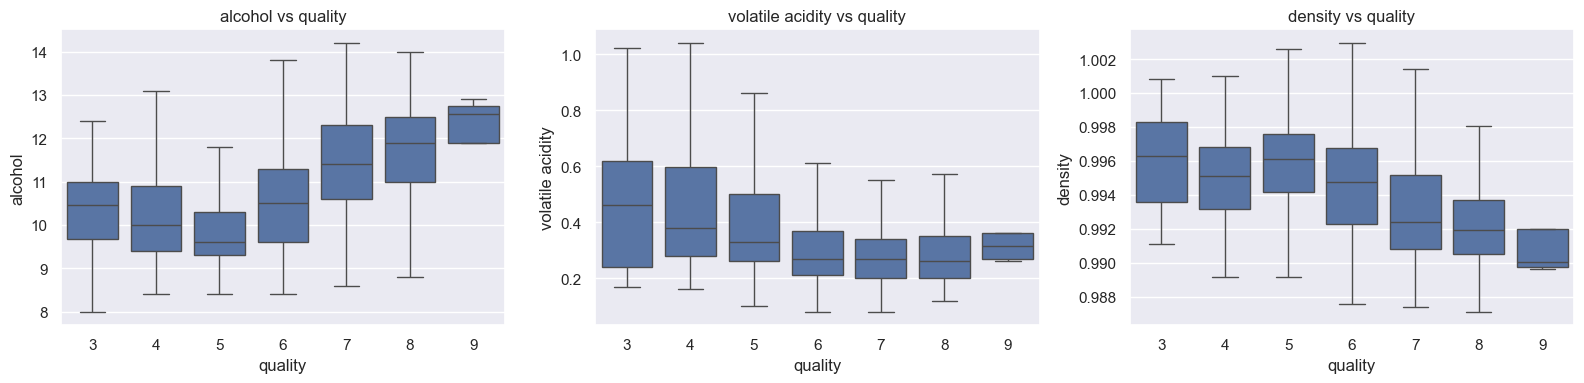

In [12]:
fig, axs = plt.subplots(figsize=(16, 4), ncols=3)
for i, feature in enumerate(["alcohol", "volatile acidity", "density"]):
    sns.boxplot(data=train, x="quality", y=feature, showfliers=False, color="C0", ax=axs[i])
    axs[i].set_title(feature + " vs quality")
plt.tight_layout()

Выводы:
- `alcohol` растёт с оценкой, но нелинейно: для оценок 3–5 медиана алкоголя примерно одинаковая (даже немного падает), а с 5 начинается уверенный рост. Линейная модель уловит общий тренд, но не этот «излом».
- `volatile acidity`, наоборот, важна в основном для плохих вин: у оценок 3–4 она заметно выше, а для 6–9 почти не меняется. Похоже на признак «дефекта»: выше какого-то порога вино получает низкую оценку. Такие пороговые зависимости хорошо ловят деревья.
- `density` падает с ростом качества, но это во многом следствие алкоголя: спирт легче воды, поэтому чем больше алкоголя, тем меньше плотность (видно на матрице корреляций ниже).

Text(0.5, 1.0, 'Корреляции между признаками')

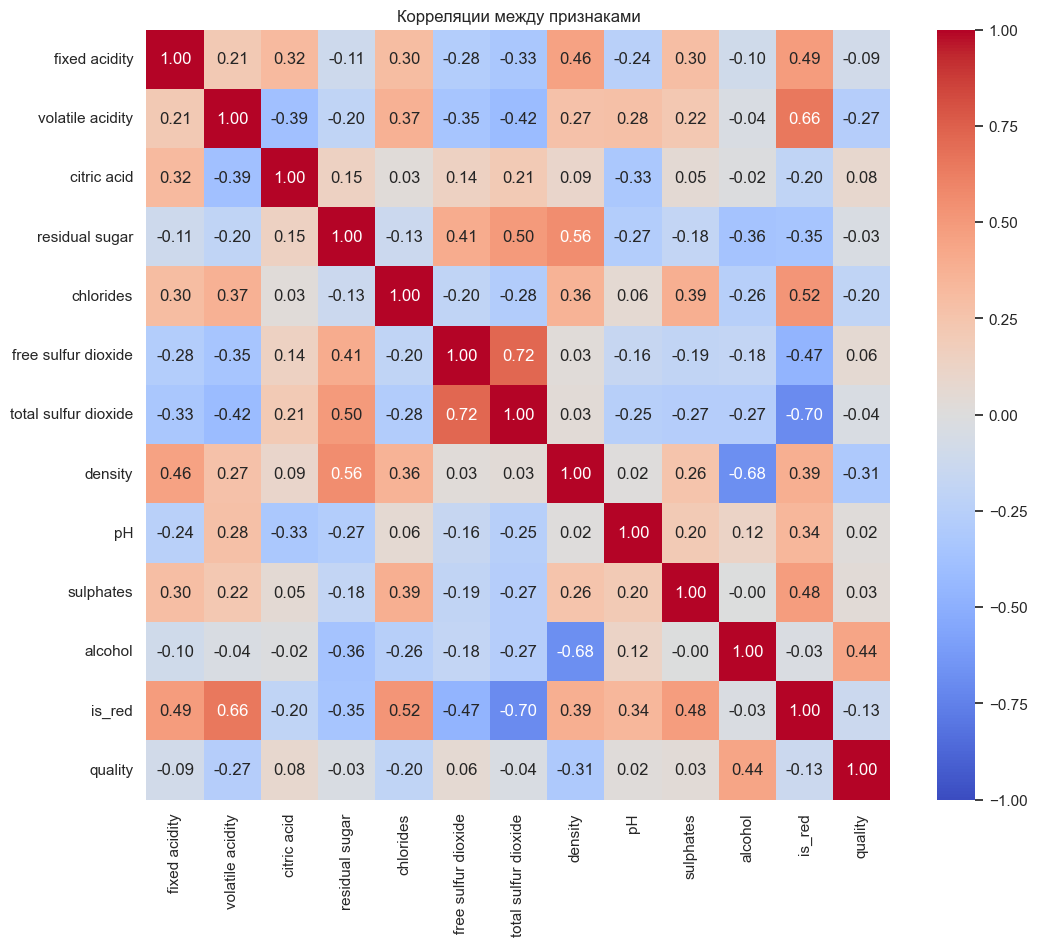

In [13]:
plt.figure(figsize=(12, 10))
sns.heatmap(train.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляции между признаками")

Выводы:
- `density` сильно связана с `alcohol` (−0.68) и `residual sugar` (0.56). Это физика: спирт легче воды, сахар тяжелее. Т.е. плотность в основном объясняется другими признаками, и её связь с качеством — во многом «отражение» алкоголя.
- `free sulfur dioxide` и `total sulfur dioxide` сильно связаны (0.72): свободный диоксид серы — это часть общего.
- `is_red` коррелирует со многими признаками (total sulfur dioxide −0.70, volatile acidity 0.66, chlorides 0.52) — это то же различие типов вина, что было видно на boxplot'ах.

Получается мультиколлинеарность. Для линейной регрессии это значит, что веса скоррелированных признаков будут неустойчивыми и их нельзя интерпретировать по отдельности (модель может дать большой отрицательный вес одному признаку и большой положительный другому, так что они друг друга компенсируют). У деревьев скоррелированные признаки будут «делить» между собой важность.

### Что я беру из анализа данных в моделирование
1. Таргет сосредоточен на 5–6, крайние оценки редкие. Ожидаю, что хуже всего модели будут предсказывать 3–4 и 8–9, это нужно проверить в анализе ошибок.
2. Главный признак — `alcohol`, дальше `density`, `volatile acidity`, `chlorides`. Ни одна связь не сильная, поэтому от простой линейной модели большого качества ждать не стоит.
3. Зависимости нелинейные (излом у алкоголя, порог у летучей кислотности) и разные для красного и белого вина. Деревья такое умеют находить сами, а линейной модели нужно помочь — добавить нелинейные признаки и взаимодействия с типом вина (часть 4).
4. У нескольких признаков сильная асимметрия и выбросы — их стоит прологарифмировать перед тем, как строить из них новые признаки.
5. Признаки в разных масштабах и скоррелированы — для линейной регрессии нужно масштабирование, а её веса нужно интерпретировать осторожно.
6. Исходные признаки оставляю все: их всего 12, пропусков нет, а слабая линейная корреляция не значит, что признак бесполезен для нелинейной модели.

# Часть 4. Новые признаки

По итогам анализа данных добавляю новые признаки. Их получают **все** модели (линейная регрессия, случайный лес и бустинг), чтобы сравнение в части 10 было честным: модели отличаются только алгоритмом, а не тем, что они видят.

Что делаю и зачем:
1. **Логарифм** (`log(1 + x)`) у признаков с длинным правым хвостом: `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, `sulphates`. Логарифм сжимает большие значения, и выбросы перестают так сильно влиять на линейную модель. Особенно это важно перед следующим шагом: если возвести в квадрат сахар 65.8, получится огромное значение, которое «перетянет» на себя всю модель.
2. **Масштабирование** (`StandardScaler`), чтобы все признаки были в одном масштабе перед их перемножением.
3. **Полиномиальные признаки 2-й степени** (`PolynomialFeatures(degree=2)`): квадраты всех признаков и все попарные произведения.
   - **Квадраты** позволяют линейной модели описывать изломы и изгибы, например то, что алкоголь почти не влияет на оценку до 5 баллов, а потом начинает сильно её повышать.
   - **Произведения** описывают взаимодействия признаков. Самые важные из них — произведения с `is_red`: по сути, это отдельный наклон для каждого признака у красного вина. В EDA мы видели, что у красного и белого вина связи с качеством разные (летучая кислотность, сульфаты, лимонная кислота), а с одним общим весом линейная модель этого учесть не может.

Можно было бы взять только то, что прямо подсказал анализ (квадраты и произведения с `is_red`), но я беру все попарные произведения: какой набор лучше, проверю по кросс-валидации в части 7, где сравню несколько вариантов, включая «набор из EDA».

Все три шага собраны в функцию `make_features()`, и она ставится в начало `Pipeline` каждой модели. Поэтому параметры масштабирования считаются только по train (а при кросс-валидации — только по обучающим фолдам), утечки нет. Логарифм и полиномы ничего не «учат» по данным, это просто формулы.

Сначала посмотрю, что логарифм делает с распределениями.

In [14]:
skewed = ["residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide", "sulphates"]

pd.DataFrame({
    "skew до": X_train[skewed].skew(),
    "skew после log": np.log1p(X_train[skewed]).skew(),
}).round(2)

,skew до,skew после log
residual sugar,1.49,0.41
chlorides,5.24,4.40
free sulfur dioxide,1.28,-0.72
total sulfur dioxide,0.01,-1.35
sulphates,1.64,1.02


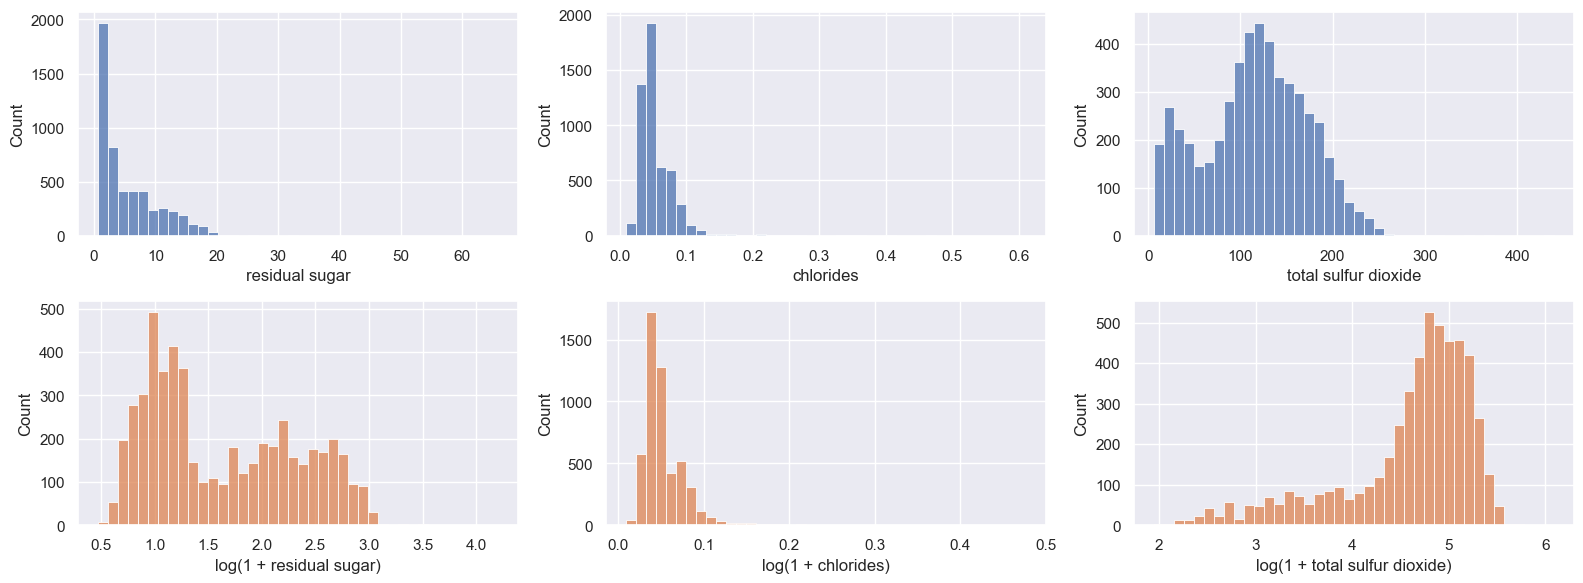

In [15]:
fig, axs = plt.subplots(figsize=(16, 6), nrows=2, ncols=3)
for i, feature in enumerate(["residual sugar", "chlorides", "total sulfur dioxide"]):
    sns.histplot(X_train[feature], bins=40, ax=axs[0, i])
    sns.histplot(np.log1p(X_train[feature]), bins=40, color="C1", ax=axs[1, i])
    axs[1, i].set_xlabel("log(1 + %s)" % feature)
plt.tight_layout()

Вывод: логарифм заметно уменьшает асимметрию `residual sugar` (1.49 → 0.41) и `sulphates` (1.64 → 1.02), у `free sulfur dioxide` хвост даже слегка переворачивается. У `chlorides` эффект слабый (5.24 → 4.40): значения хлоридов маленькие (около 0.05), а при маленьких `x` функция `log(1 + x)` почти не отличается от `x`. У `total sulfur dioxide` асимметрии изначально почти нет — у него два пика (белое и красное вино), и после логарифма появляется хвост влево.

Т.е. логарифм не делает распределения «идеальными», но главное он делает: сжимает самые большие значения. Нужен ли он на самом деле, проверю не на глаз, а по кросс-валидации в части 7: сравню полиномиальные признаки с логарифмом и без него.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer

other = [col for col in X_train.columns if col not in skewed]

def make_features():
    return [
        ("log", ColumnTransformer([
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), skewed),
            ("rest", "passthrough", other)
        ], verbose_feature_names_out=False)),
        ("scaling", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ]

def term_names(model):
    inputs = model.named_steps["log"].get_feature_names_out()
    names = []
    for powers in model.named_steps["poly"].powers_:
        parts = [name + "²" if p == 2 else name for name, p in zip(inputs, powers) if p > 0]
        names.append(" × ".join(parts))
    return names

features_pipeline = Pipeline(make_features())
X_train_new = features_pipeline.fit_transform(X_train)
new_names = term_names(features_pipeline)

print(X_train.shape, "->", X_train_new.shape)
print("Исходные (после log):", new_names[:12])
print("Квадраты, например:", [name for name in new_names if "²" in name][:4])
print("Произведения, например:", [name for name in new_names if "×" in name][:4])

(5197, 12) -> (5197, 90)
Исходные (после log): ['residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'sulphates', 'fixed acidity', 'volatile acidity', 'citric acid', 'density', 'pH', 'alcohol', 'is_red']
Квадраты, например: ['residual sugar²', 'chlorides²', 'free sulfur dioxide²', 'total sulfur dioxide²']
Произведения, например: ['residual sugar × chlorides', 'residual sugar × free sulfur dioxide', 'residual sugar × total sulfur dioxide', 'residual sugar × sulphates']


Вывод: из 12 исходных признаков получилось 90: сами 12 признаков, 12 квадратов и 66 попарных произведений. Для линейной модели это значит, что она сможет описывать изгибы и разные наклоны для красного и белого вина. Но и параметров у неё стало в 7.5 раз больше, поэтому без регуляризации тут легко переобучиться — это проверю в части 7.

Для деревьев логарифм и масштабирование ничего не меняют: это монотонные преобразования, и дерево разобьёт данные теми же порогами. А вот произведения признаков — новая информация: дерево разбивает данные только по одному признаку за раз, и с готовыми произведениями ему проще найти взаимодействия.

# Часть 5. Метрики

$$\text{MAE} = \frac{1}{\ell}\sum_{i=1}^{\ell} |y_i - a(x_i)|, \qquad \text{RMSE} = \sqrt{\frac{1}{\ell}\sum_{i=1}^{\ell} (y_i - a(x_i))^2}$$

**Что показывает MAE.** Среднее абсолютное отклонение предсказания от правильного ответа, в тех же единицах, что и `quality` (в баллах). MAE = 0.5 значит, что в среднем модель ошибается на полбалла. Каждая ошибка входит в среднее пропорционально своей величине.

**Что показывает RMSE.** Корень из среднего квадрата ошибки. Тоже измеряется в баллах, но это не «средняя ошибка», а скорее типичный размер ошибки, в котором большие ошибки весят больше. Минимизировать RMSE — то же самое, что минимизировать MSE, а именно MSE по умолчанию оптимизируют линейная регрессия и деревья в sklearn.

**Почему RMSE сильнее реагирует на большие ошибки.** Перед усреднением ошибки возводятся в квадрат. Ошибка в 2 балла даёт вклад 4, а ошибка в 0.5 балла — 0.25, т.е. в 16 раз меньше (в MAE — только в 4 раза). Поэтому одна большая ошибка увеличивает RMSE сильнее, чем много мелких.

**Почему для одной и той же модели MAE и RMSE могут заметно различаться.** Всегда RMSE ≥ MAE (среднее квадратичное не меньше среднего арифметического), и равны они только тогда, когда все ошибки одинаковы по модулю. Чем неоднороднее ошибки, т.е. чем больше среди них редких, но крупных, тем больше разрыв. Так что по отношению RMSE/MAE можно понять, есть ли у модели «выбросы» в ошибках. В этой задаче я этого как раз жду: на типичных винах (5–6) модель будет ошибаться мало, а на редких (3, 8, 9) — сильно.

Для удобства заведу функцию, которая считает обе метрики на тесте и складывает их в общую таблицу результатов (туда же записываю CV RMSE на train).

In [17]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

results = {}

def evaluate(name, y_true, y_pred, cv_rmse=np.nan):
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    results[name] = {"RMSE": rmse, "MAE": mae, "CV RMSE": cv_rmse}
    print("%s: Test RMSE = %.4f, Test MAE = %.4f" % (name, rmse, mae))

**Схема валидации.** Все решения (гиперпараметры, выбор лучшей модели) принимаю по кросс-валидации на train: 5 фолдов с перемешиванием и фиксированным `random_state`, один и тот же объект `cv` для всех моделей, чтобы они сравнивались на одинаковых разбиениях. Тест используется только для финальной оценки.

In [18]:
from sklearn.model_selection import KFold, cross_val_score, RandomizedSearchCV

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Часть 6. Baseline

В качестве baseline предсказываю одну константу для всех объектов. Какую константу брать, зависит от метрики:
- для MSE/RMSE оптимальная константа — **среднее** значение таргета: если продифференцировать $\sum_i (y_i - c)^2$ по $c$ и приравнять к нулю, получится $c = \frac{1}{\ell}\sum_i y_i$;
- для MAE оптимальная константа — **медиана**.

Основная метрика — RMSE, поэтому baseline = среднее `quality` по **train** (тест для подсчёта константы не используется).

In [19]:
from sklearn.dummy import DummyRegressor

best_constant = y_train.mean()
print("Best constant (mean of y_train) = %.4f" % best_constant)

cv_scores = cross_val_score(DummyRegressor(strategy="mean"), X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print("Mean CV RMSE = %.4f" % np.mean(-cv_scores))

y_pred_baseline = best_constant * np.ones(y_test.shape)
evaluate("Baseline", y_test, y_pred_baseline, np.mean(-cv_scores))

# для сравнения: медиана - оптимальная константа для MAE
median_constant = y_train.median()
y_pred_median = median_constant * np.ones(y_test.shape)
print("Median constant = %.1f: Test RMSE = %.4f, Test MAE = %.4f" % (median_constant, root_mean_squared_error(y_test, y_pred_median), mean_absolute_error(y_test, y_pred_median)))

Best constant (mean of y_train) = 5.8182
Mean CV RMSE = 0.8732
Baseline: Test RMSE = 0.8738, Test MAE = 0.6861
Median constant = 6.0: Test RMSE = 0.8923, Test MAE = 0.6377


Вывод: baseline даёт на тесте RMSE = 0.874 — почти ровно стандартное отклонение `quality` (0.873). Так и должно быть: RMSE константы, равной среднему, и есть std таргета. Значит, полезная модель должна давать RMSE заметно меньше 0.87, а порог 0.70 — это на 20% лучше константы.

Медиана (6) даёт RMSE хуже (0.892), но MAE лучше (0.638 против 0.686). Это подтверждает, что для разных метрик оптимальны разные константы. В таблицу записываю среднее, т.к. основная метрика — RMSE.

# Часть 7. Линейная регрессия

Сначала строю обычную линейную регрессию на **исходных** 12 признаках (`Pipeline` из `StandardScaler` и `LinearRegression`). Её я использую для анализа коэффициентов: у 12 признаков веса ещё можно прочитать и сравнить, а у 90 полиномиальных — уже сложно. В итоговую таблицу пойдёт линейная модель на новых признаках (ниже), чтобы все модели в сравнении были на одинаковых признаках.

Pipeline нужен, чтобы при кросс-валидации scaler обучался (считал среднее и std) только на обучающих фолдах, а не на всём train, иначе в обучение протекает информация из валидационного фолда.

Требуется ли масштабирование? На качество обычной линейной регрессии (без регуляризации) масштабирование не влияет: если признак умножить на число, вес просто поделится на это число, и предсказания останутся теми же. Но оно сильно влияет на **интерпретацию коэффициентов**, это разберу ниже.

In [20]:
from sklearn.linear_model import LinearRegression

base_linear = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", LinearRegression())
])

cv_scores = cross_val_score(base_linear, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print("Cross validation scores:\n\t", "\n\t".join("%.4f" % x for x in -cv_scores))
base_linear_cv = np.mean(-cv_scores)
print("Mean CV RMSE = %.4f" % base_linear_cv)

base_linear.fit(X_train, y_train)
print("Train RMSE = %.4f" % root_mean_squared_error(y_train, base_linear.predict(X_train)))
print("Test RMSE = %.4f (для справки, в итоговую таблицу не идёт)" % root_mean_squared_error(y_test, base_linear.predict(X_test)))

Cross validation scores:
	 0.7346
	0.7194
	0.7580
	0.7454
	0.7309
Mean CV RMSE = 0.7377
Train RMSE = 0.7337
Test RMSE = 0.7280 (для справки, в итоговую таблицу не идёт)


Вывод: линейная регрессия на исходных признаках даёт CV RMSE = 0.738 (на тесте 0.728 — для справки). Это на 16% лучше baseline (0.873 на CV), т.е. модель извлекает из признаков полезную информацию, но порог 0.70 не проходит.

Ошибка на train (0.734) почти такая же, как на CV, значит переобучения нет. Наоборот, модель **недообучена**: она слишком простая для этих данных. После анализа данных это ожидаемо: зависимости нелинейные (излом у алкоголя, порог у летучей кислотности) и различаются для красного и белого вина, а линейная модель может только сложить признаки с весами. Разброс по фолдам небольшой (0.72–0.76), так что оценка стабильная. Как раз для этого в части 4 добавлены новые признаки — ниже проверю, насколько они помогают.

In [21]:
def show_weights(features, weights, scales, title):
    fig, axs = plt.subplots(figsize=(14, 5), ncols=2)
    sorted_weights = sorted(zip(weights, features, scales), reverse=True)
    weights = [x[0] for x in sorted_weights]
    features = [x[1] for x in sorted_weights]
    scales = [x[2] for x in sorted_weights]
    sns.barplot(y=features, x=weights, color="C0", ax=axs[0])
    axs[0].set_xlabel("Weight")
    axs[0].set_title(title)
    sns.barplot(y=features, x=scales, color="C1", ax=axs[1])
    axs[1].set_xlabel("Scale (std)")
    plt.tight_layout()

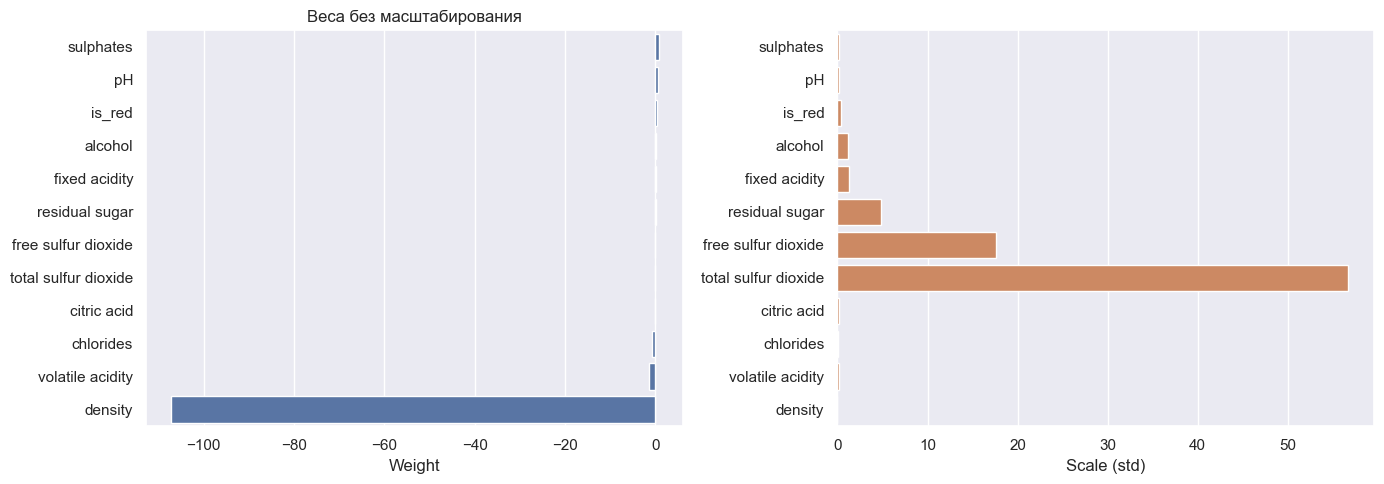

In [22]:
raw_model = LinearRegression().fit(X_train, y_train)
show_weights(X_train.columns, raw_model.coef_, X_train.std(), "Веса без масштабирования")

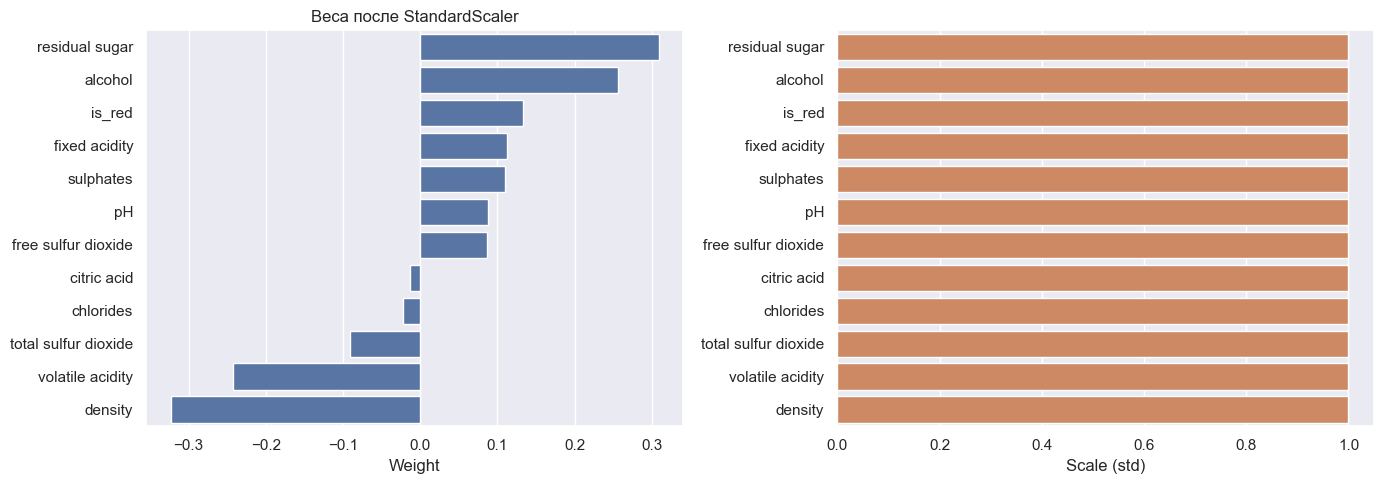

In [23]:
scaler = base_linear.named_steps["scaling"]
linear_model = base_linear.named_steps["regression"]
X_train_scaled = scaler.transform(X_train)

show_weights(X_train.columns, linear_model.coef_, X_train_scaled.std(axis=0), "Веса после StandardScaler")

In [24]:
coefs = pd.DataFrame({
    "вес без масштабирования": raw_model.coef_,
    "std признака": scaler.scale_,
    "вес после масштабирования": linear_model.coef_,
}, index=X_train.columns)
coefs["|вес после масштабирования|"] = coefs["вес после масштабирования"].abs()
coefs.sort_values("|вес после масштабирования|", ascending=False).round(4)

,вес без масштабирования,std признака,вес после масштабирования,|вес после масштабирования|
density,-107.2543,0.0030,-0.3230,0.3230
residual sugar,0.0645,4.7851,0.3086,0.3086
alcohol,0.2152,1.1888,0.2558,0.2558
volatile acidity,-1.4620,0.1657,-0.2423,0.2423
is_red,0.3089,0.4323,0.1335,0.1335
fixed acidity,0.0872,1.2860,0.1121,0.1121
sulphates,0.7447,0.1468,0.1093,0.1093
total sulfur dioxide,-0.0016,56.7329,-0.0909,0.0909
pH,0.5483,0.1607,0.0881,0.0881
free sulfur dioxide,0.0049,17.6453,0.0861,0.0861


Выводы по коэффициентам:
- **Без масштабирования** сравнивать веса нельзя. У `density` вес ≈ −107, а у остальных признаков — порядка 0.001–1. Но это не значит, что плотность в 100 раз важнее: она меняется в пределах ~0.003, поэтому вес огромный, а реальный вклад в предсказание (вес × std признака) ≈ −107 × 0.003 ≈ −0.32 балла. И наоборот, у `total sulfur dioxide` вес всего −0.0016, но сам признак меняется на десятки единиц.
- **После StandardScaler** вес показывает, на сколько баллов меняется предсказание, если признак увеличить на одно стандартное отклонение (при остальных фиксированных). В таблице видно, что вес после масштабирования = вес до × std признака. Теперь веса можно сравнивать между собой.
- Наибольшее влияние в линейной модели у `density` (−0.32), `residual sugar` (+0.31), `alcohol` (+0.26) и `volatile acidity` (−0.24), дальше идут `is_red`, `fixed acidity`, `sulphates`.

Здесь же видна мультиколлинеарность, найденная в EDA. `residual sugar` получил большой **положительный** вес (+0.31), хотя его корреляция с качеством около нуля (−0.03), а у `density` вес по модулю больше, чем у алкоголя. Дело в том, что плотность почти определяется алкоголем и сахаром, и модель использует эти три признака в комбинации: «больше сахара при той же плотности» фактически означает «больше алкоголя». Поэтому эти веса нельзя читать как независимый эффект каждого признака, они сильно зависят от того, какие ещё признаки есть в модели. Похожая история с `is_red`: вес положительный (+0.13), хотя красные вина в среднем оценены ниже. То есть при одинаковой химии красное предсказывается даже выше, а низкие оценки красных объясняются их более высокой летучей кислотностью и т.п.

Надёжные выводы, которые совпадают с EDA: алкоголь повышает предсказание, летучая кислотность понижает.

### Линейная регрессия на новых признаках

Теперь та же линейная модель, но на 90 новых признаках из части 4. Признаков стало много, и многие из них сильно скоррелированы (например, `alcohol` и `alcohol²`), поэтому обычная `LinearRegression` может переобучиться и выдать огромные неустойчивые веса. Сначала проверю её как есть, а потом возьму `Ridge` — линейную регрессию с L2-регуляризацией — и подберу силу регуляризации `alpha` случайным поиском по логарифмической шкале.

Перед `Ridge` после полиномиальных признаков ещё раз ставлю `StandardScaler`: регуляризация штрафует все веса одинаково, и признаки должны быть в одном масштабе (квадраты и произведения имеют другой разброс, чем исходные признаки).

In [25]:
plain_fe = Pipeline(make_features() + [("scaling2", StandardScaler()), ("regression", LinearRegression())])
cv_scores = cross_val_score(plain_fe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
plain_fe_cv = np.mean(-cv_scores)
print("LinearRegression на новых признаках без регуляризации: CV RMSE = %.4f" % plain_fe_cv)

LinearRegression на новых признаках без регуляризации: CV RMSE = 0.7115


Best alpha = 19.1854
Best CV RMSE = 0.7026


Text(0.5, 1.0, 'Ridge на новых признаках: подбор alpha')

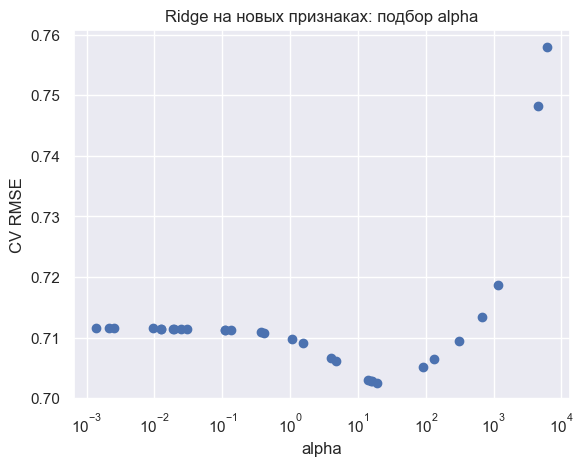

In [26]:
from sklearn.linear_model import Ridge
from scipy.stats import loguniform

ridge_pipeline = Pipeline(make_features() + [
    ("scaling2", StandardScaler()),
    ("regression", Ridge())
])

ridge_searcher = RandomizedSearchCV(
    ridge_pipeline,
    {"regression__alpha": loguniform(1e-3, 1e4)},
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
ridge_searcher.fit(X_train, y_train)

print("Best alpha = %.4f" % ridge_searcher.best_params_["regression__alpha"])
print("Best CV RMSE = %.4f" % -ridge_searcher.best_score_)

alphas = ridge_searcher.cv_results_["param_regression__alpha"].data.astype(float)
plt.scatter(alphas, -ridge_searcher.cv_results_["mean_test_score"])
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("CV RMSE")
plt.title("Ridge на новых признаках: подбор alpha")

Теперь проверю, какой набор признаков лучше для линейной модели. Для каждого набора делаю одно и то же: `Ridge` с подбором `alpha` случайным поиском на тех же фолдах. Среди вариантов:
- исходные признаки и только логарифм;
- **набор, который прямо вытекает из EDA**: логарифм + квадраты (изгибы) + произведения с `is_red` (разные наклоны для красного и белого) — 34 признака;
- те же наборы без логарифма — чтобы понять, нужен ли он;
- полный набор из части 4 (90 признаков).

Квадраты и произведения в «наборе из EDA» строю из тех же отмасштабированных признаков, что и в полном наборе.

In [27]:
def expand(X, squares=True, red_inter=True):
    # X - уже отмасштабированные признаки, последний столбец - is_red
    numeric_part, is_red = X[:, :-1], X[:, -1:]
    parts = [X]
    if squares:
        parts.append(numeric_part ** 2)
    if red_inter:
        parts.append(numeric_part * is_red)
    return np.hstack(parts)

def make_subset(log=True, squares=True, red_inter=True):
    steps = make_features()[:2] if log else [("scaling", StandardScaler())]
    steps.append(("expand", FunctionTransformer(expand, kw_args={"squares": squares, "red_inter": red_inter})))
    return steps

feature_sets = {
    "исходные признаки": [("scaling", StandardScaler())],
    "log": make_features()[:2],
    "log + квадраты": make_subset(squares=True, red_inter=False),
    "log + произведения с is_red": make_subset(squares=False, red_inter=True),
    "log + квадраты + произведения с is_red (из EDA)": make_subset(),
    "квадраты + произведения с is_red, без log": make_subset(log=False),
    "все полиномы, без log": make_features()[1:],
    "log + все полиномы (выбранный набор)": make_features(),
}

sets_check = {}
for name, steps in feature_sets.items():
    searcher = RandomizedSearchCV(
        Pipeline(steps + [("scaling2", StandardScaler()), ("regression", Ridge())]),
        {"regression__alpha": loguniform(1e-3, 1e4)},
        n_iter=30,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    searcher.fit(X_train, y_train)
    sets_check[name] = {
        "признаков": searcher.best_estimator_[:-2].transform(X_train.iloc[:5]).shape[1],
        "alpha": searcher.best_params_["regression__alpha"],
        "CV RMSE": -searcher.best_score_,
        "CV std": searcher.cv_results_["std_test_score"][searcher.best_index_],
    }

sets_check = pd.DataFrame(sets_check).T
sets_check["признаков"] = sets_check["признаков"].astype(int)
print("LinearRegression без регуляризации: исходные признаки CV RMSE = %.4f, все новые признаки CV RMSE = %.4f" % (base_linear_cv, plain_fe_cv))
sets_check.round(4)

LinearRegression без регуляризации: исходные признаки CV RMSE = 0.7377, все новые признаки CV RMSE = 0.7115


,признаков,alpha,CV RMSE,CV std
исходные признаки,12,19.1854,0.7376,0.0133
log,12,90.4707,0.7334,0.0125
log + квадраты,23,313.4958,0.7408,0.0238
log + произведения с is_red,23,133.0325,0.7289,0.0110
log + квадраты + произведения с is_red (из EDA),34,19.1854,0.7245,0.0256
"квадраты + произведения с is_red, без log",34,0.0014,0.7386,0.0229
"все полиномы, без log",90,90.4707,0.7170,0.0068
log + все полиномы (выбранный набор),90,19.1854,0.7026,0.0132


Выводы:
- **Гипотезы из EDA подтверждаются частично.** Произведения с `is_red` (разные наклоны для красного и белого) дают самый «чистый» выигрыш: CV RMSE 0.733 → 0.729 при маленьком разбросе по фолдам (0.011). А квадраты сами по себе делают только хуже (0.741), и разброс по фолдам вырастает вдвое (0.024): квадраты оставшихся выбросов (у `chlorides` длинный хвост остаётся и после логарифма) портят отдельные фолды. Набор из EDA целиком (34 признака) даёт 0.725 — лучше исходных признаков, но с большим разбросом (0.026).
- **Полный набор (90 признаков) заметно лучше всех: 0.703**, при этом разброс по фолдам такой же маленький, как у исходных признаков (0.013). Значит, кроме изгибов и разницы между типами вина, важны ещё и взаимодействия между химическими признаками — в EDA мы их не рассматривали, но модель их находит (см. веса ниже).
- **Логарифм нужен**: без него и набор из EDA (0.739 против 0.725), и полный набор (0.717 против 0.703) заметно хуже. Т.е. главное, что делает логарифм, — сжимает выбросы, которые иначе раздуваются при возведении в квадрат и перемножении.
- **Регуляризация теперь нужна**: `LinearRegression` на тех же 90 признаках даёт 0.712, а `Ridge` — 0.703. На 12 исходных признаках регуляризация ничего не давала, а здесь признаков много и они сильно скоррелированы (например, `alcohol` и `alcohol²`), поэтому без штрафа веса начинают подстраиваться под шум.

Итого по кросс-валидации выбираю полный набор из 90 признаков. Анализ данных подсказал направление (нелинейность и разные наклоны для типов вина), а конкретный набор выбран по CV, а не по тому, «что красивее».

In [28]:
linear_fe = ridge_searcher.best_estimator_
y_pred_linear = linear_fe.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, linear_fe.predict(X_train)))
evaluate("Linear Regression (Ridge)", y_test, y_pred_linear, -ridge_searcher.best_score_)

Train RMSE = 0.6866
Linear Regression (Ridge): Test RMSE = 0.6945, Test MAE = 0.5421


Вывод: `Ridge` с `alpha` ≈ 19 на новых признаках даёт CV RMSE = 0.703 и на тесте RMSE = 0.695, MAE = 0.542. По сравнению с линейной регрессией на исходных признаках это −0.035 на CV и −0.034 на тесте — новые признаки действительно убрали большую часть недообучения. Порог 0.70 на тесте пройден, но по CV модель ровно на границе (0.703), так что запас минимальный.

Переобучения почти нет: на train 0.687, на CV 0.703. Регуляризация держит 90 признаков под контролем.

density                                   -0.398
residual sugar                             0.270
volatile acidity                          -0.255
density × is_red                           0.166
alcohol                                    0.165
total sulfur dioxide × volatile acidity    0.142
residual sugar × density                   0.139
volatile acidity × is_red                  0.139
density²                                   0.135
fixed acidity                              0.125
alcohol × is_red                           0.123
fixed acidity²                            -0.118
total sulfur dioxide                      -0.117
free sulfur dioxide²                      -0.117
free sulfur dioxide × is_red              -0.115
dtype: float64

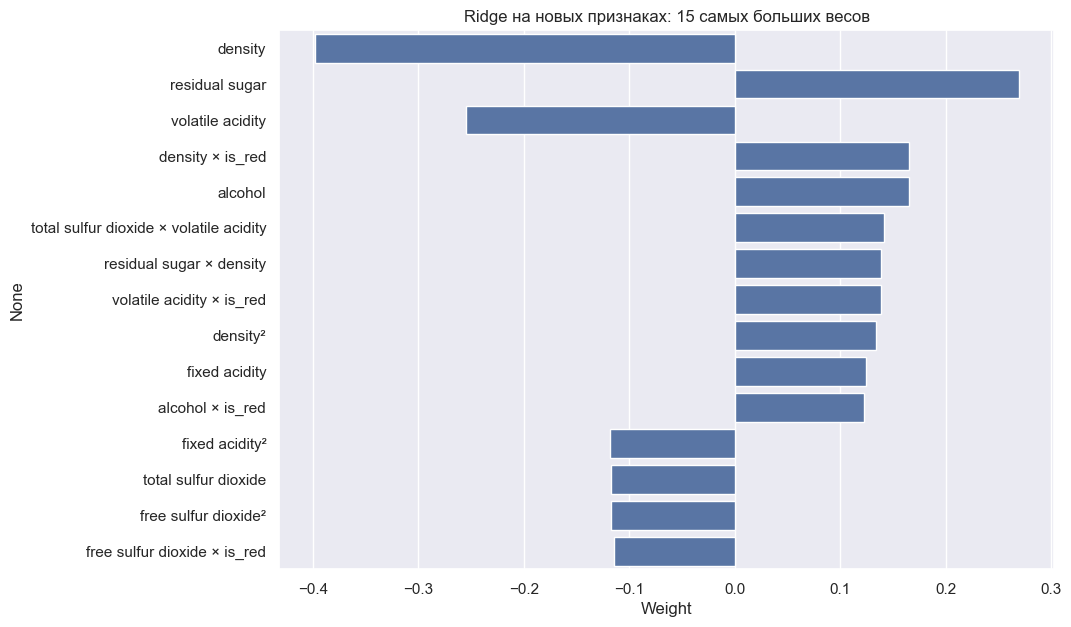

In [29]:
ridge_coefs = pd.Series(linear_fe.named_steps["regression"].coef_, index=term_names(linear_fe))
top_coefs = ridge_coefs.reindex(ridge_coefs.abs().sort_values(ascending=False).index).head(15)

plot = sns.barplot(y=top_coefs.index, x=top_coefs, color="C0")
plot.figure.set_size_inches(10, 7)
plt.title("Ridge на новых признаках: 15 самых больших весов")
plt.xlabel("Weight")

top_coefs.round(3)

Выводы по весам (признаки отмасштабированы, поэтому веса можно сравнивать по величине, но с оговоркой ниже):
- **Главные эффекты те же, что и у простой линейной регрессии**: `density` (−0.40), `residual sugar` (+0.27), `volatile acidity` (−0.26), `alcohol` (+0.17). Плотность и сахар опять получили большие веса противоположных знаков — та же мультиколлинеарность «плотность ≈ алкоголь + сахар», что и в простой модели.
- **Разные наклоны для красного и белого**: в топе 4 произведения с `is_red` — для `density`, `volatile acidity`, `alcohol` и `free sulfur dioxide`. Это ровно то, что мы видели в EDA: у красного и белого вина эти признаки по-разному связаны с качеством. Простая линейная модель с одним весом на признак такого учесть не могла.
- **Изгибы**: квадраты `density²`, `fixed acidity²` и `free sulfur dioxide²`. Отрицательный вес у `free sulfur dioxide²` значит, что зависимость похожа на перевёрнутую «U»: и слишком мало, и слишком много свободного SO₂ — плохо. Это логично химически: мало SO₂ — вино хуже защищено от окисления, много — появляется запах серы.
- **Взаимодействия химических признаков**: `total sulfur dioxide × volatile acidity`, `residual sugar × density`. Их как раз нет в «наборе из EDA», и, видимо, поэтому он проигрывает полному.

Оговорка: полиномиальные признаки сильно скоррелированы между собой (`alcohol`, `alcohol²`, `alcohol × is_red`, ...), поэтому отдельный вес нельзя читать как «эффект этого признака при остальных фиксированных» — нельзя изменить `alcohol`, не изменив `alcohol²`. Эффект исходного признака складывается из всех слагаемых, где он участвует.

# Часть 8. Random Forest

Случайный лес — это усреднение многих глубоких решающих деревьев, каждое из которых обучено на бутстрап-выборке и при каждом разбиении выбирает из случайного подмножества признаков. Деревья умеют находить нелинейные и пороговые зависимости и взаимодействия признаков (например, разные правила для красного и белого вина), а усреднение уменьшает разброс отдельных деревьев.

Лес обучаю на тех же 90 признаках из части 4, что и линейную модель: `make_features()` стоит в начале пайплайна. Масштабирование и логарифм для деревьев ничего не меняют (разбиение — это порог вида «признак < t», и при монотонном преобразовании меняется только значение порога), а произведения признаков могут помочь найти взаимодействия.

Гиперпараметры подбираю через `RandomizedSearchCV` на тех же 5 фолдах (у параметров приставка `model__`, потому что модель стоит в пайплайне):
- `n_estimators` — число деревьев (больше — стабильнее, но дольше);
- `max_depth`, `min_samples_split`, `min_samples_leaf` — ограничивают сложность каждого дерева;
- `max_features` — сколько признаков рассматривать при каждом разбиении (меньше — деревья разнообразнее).

Почему случайный поиск, а не полный перебор по сетке: параметров 5, и полная сетка из всех комбинаций — это тысячи обучений леса. Случайный поиск за фиксированный бюджет (30 комбинаций) пробует больше разных значений каждого параметра, а обычно на качество сильно влияют лишь 1–2 параметра, поэтому этого хватает.

In [30]:
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import randint

rf_params = {
    "model__n_estimators": randint(100, 600),
    "model__max_depth": [None, 10, 15, 20, 30],
    "model__min_samples_split": randint(2, 11),
    "model__min_samples_leaf": randint(1, 6),
    "model__max_features": ["sqrt", 0.3, 0.5, 0.7, 1.0],
}

rf_searcher = RandomizedSearchCV(
    Pipeline(make_features() + [("model", RandomForestRegressor(random_state=RANDOM_STATE))]),
    rf_params,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_searcher.fit(X_train, y_train)

print("Best params:", rf_searcher.best_params_)
print("Best CV RMSE = %.4f" % -rf_searcher.best_score_)

Best params: {'model__max_depth': 30, 'model__max_features': 0.3, 'model__min_samples_leaf': 2, 'model__min_samples_split': 3, 'model__n_estimators': 301}
Best CV RMSE = 0.6185


In [31]:
rf_cv_results = pd.DataFrame(rf_searcher.cv_results_).rename(columns=lambda col: col.replace("param_model__", ""))
rf_cv_results["CV RMSE"] = -rf_cv_results["mean_test_score"]
rf_cv_results = rf_cv_results.sort_values("CV RMSE")
rf_cv_results[["n_estimators", "max_depth", "min_samples_split", "min_samples_leaf", "max_features", "CV RMSE", "std_test_score"]].head(10)

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,CV RMSE,std_test_score
13,301,30,3,2,0.3,0.618455,0.012804
11,149,30,5,1,0.5,0.619251,0.012545
21,506,20,8,1,0.3,0.620248,0.013064
12,409,20,5,2,0.3,0.620367,0.012858
8,188,30,5,2,sqrt,0.622185,0.014049
19,589,15,6,1,0.5,0.622666,0.012177
23,200,15,4,1,0.5,0.622900,0.013846
14,312,20,9,1,0.7,0.623068,0.011834
17,108,30,8,1,sqrt,0.623855,0.011861
6,463,15,4,2,0.5,0.623977,0.012438


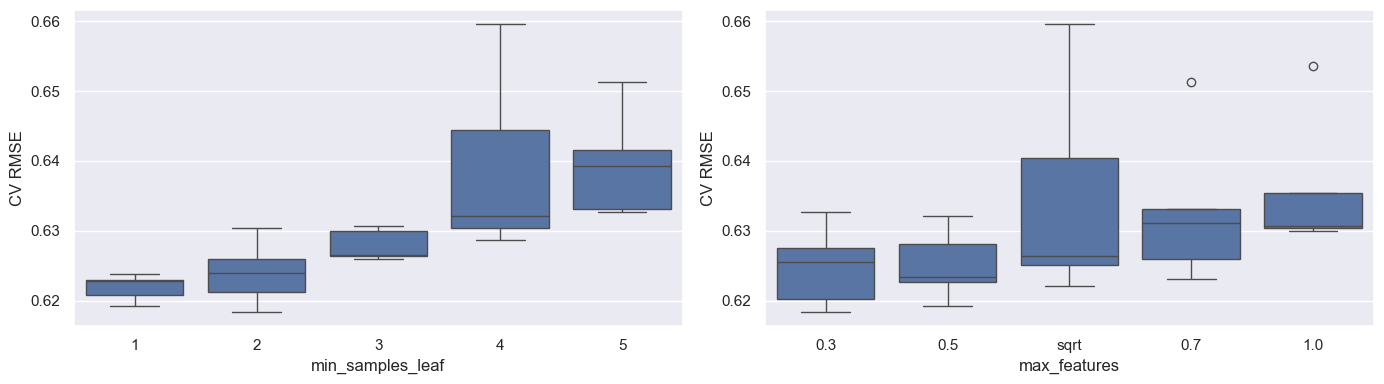

In [32]:
fig, axs = plt.subplots(figsize=(14, 4), ncols=2)
sns.boxplot(data=rf_cv_results, x="min_samples_leaf", y="CV RMSE", color="C0", ax=axs[0])
sns.boxplot(data=rf_cv_results, x="max_features", y="CV RMSE", color="C0", ax=axs[1])
plt.tight_layout()

In [33]:
rf_model = rf_searcher.best_estimator_
y_pred_rf = rf_model.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, rf_model.predict(X_train)))
evaluate("Random Forest", y_test, y_pred_rf, -rf_searcher.best_score_)

Train RMSE = 0.2719
Random Forest: Test RMSE = 0.5976, Test MAE = 0.4340


Вывод:
- Лучшая комбинация: `max_depth=30`, `min_samples_leaf=2`, `min_samples_split=3`, `max_features=0.3`, 301 дерево. CV RMSE = 0.619, на тесте RMSE = 0.598, MAE = 0.434. Порог пройден с запасом, ошибка на 32% меньше, чем у baseline.
- Лучшее `max_features` теперь 0.3: при 90 признаках дерево и так видит на каждом разбиении 27 признаков, этого достаточно, а меньшее подмножество делает деревья разнообразнее.
- По графикам видно, что сильнее всего на качество влияет `min_samples_leaf`: чем меньше листья (т.е. чем точнее дерево подстраивается под отдельные объекты), тем лучше. Разница между десятью лучшими комбинациями маленькая (0.618–0.624), меньше разброса по фолдам (≈0.013).
- RMSE на train = 0.27, сильно меньше, чем на тесте. Для случайного леса это нормально (глубокие деревья почти запоминают train), важно, что CV и тест близки. То, что выгоднее всего «запоминать» отдельные объекты, связано с дубликатами — это проверю в части 12.
- Цена новых признаков для леса — время: подбор на 90 признаках идёт в десятки раз дольше, чем на 12, потому что на каждом разбиении перебирается больше признаков.

alcohol                 0.207
volatile acidity        0.114
density                 0.092
free sulfur dioxide     0.079
chlorides               0.078
residual sugar          0.067
total sulfur dioxide    0.067
sulphates               0.066
citric acid             0.064
pH                      0.061
fixed acidity           0.057
is_red                  0.047
dtype: float64

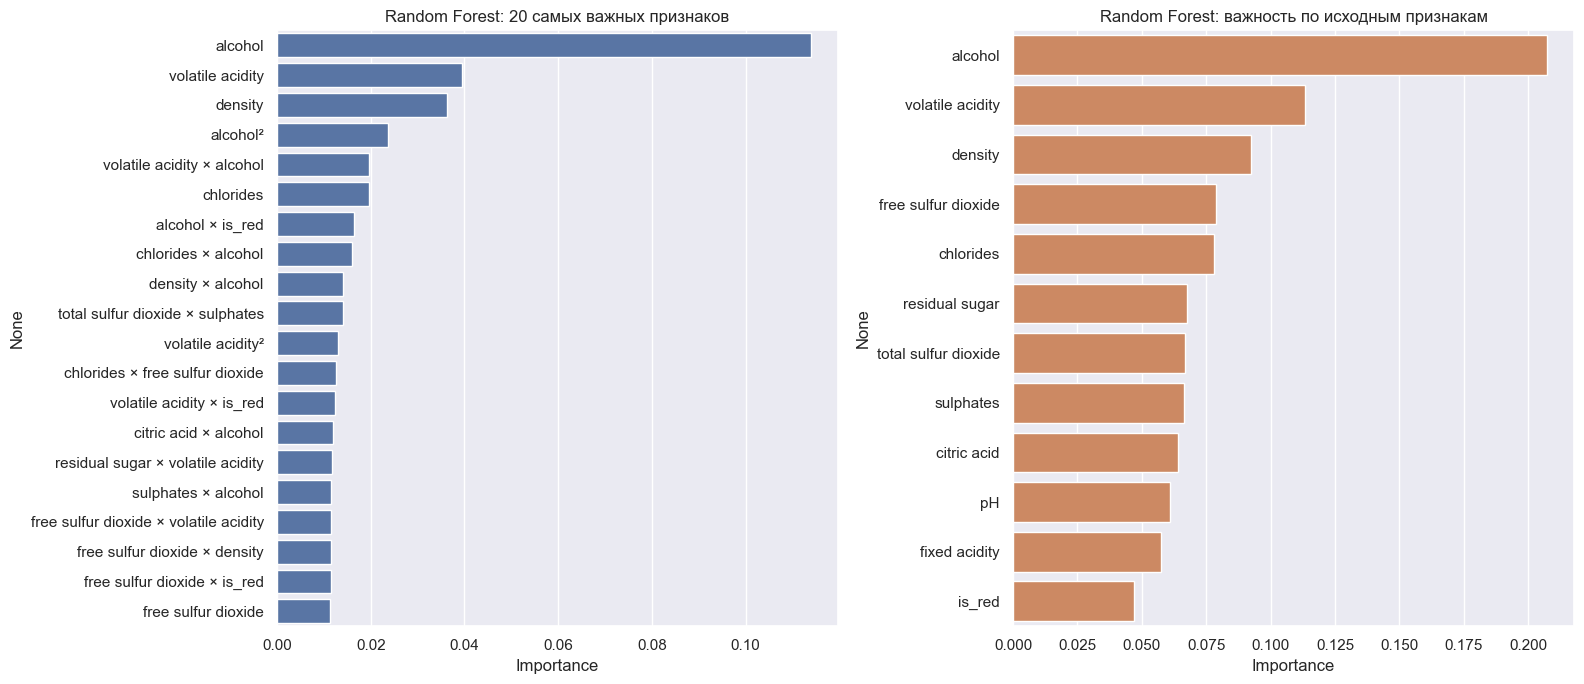

In [34]:
def importance_by_feature(model):
    # важность каждого полиномиального признака делю поровну между исходными признаками, из которых он составлен
    inputs = model.named_steps["log"].get_feature_names_out()
    result = pd.Series(0.0, index=inputs)
    for importance, powers in zip(model.named_steps["model"].feature_importances_, model.named_steps["poly"].powers_):
        used = inputs[powers > 0]
        result[used] += importance / len(used)
    return result.sort_values(ascending=False)

rf_terms = pd.Series(rf_model.named_steps["model"].feature_importances_, index=term_names(rf_model)).sort_values(ascending=False)
rf_importances = importance_by_feature(rf_model)

fig, axs = plt.subplots(figsize=(16, 7), ncols=2)
sns.barplot(y=rf_terms.head(20).index, x=rf_terms.head(20), color="C0", ax=axs[0])
axs[0].set_title("Random Forest: 20 самых важных признаков")
axs[0].set_xlabel("Importance")
sns.barplot(y=rf_importances.index, x=rf_importances, color="C1", ax=axs[1])
axs[1].set_title("Random Forest: важность по исходным признакам")
axs[1].set_xlabel("Importance")
plt.tight_layout()

rf_importances.round(3)

`feature_importances_` у случайного леса (impurity-based, MDI) показывает, насколько в сумме уменьшается MSE за счёт разбиений по признаку во всех деревьях. Слева — важность каждого из 90 признаков, справа — важность, собранная обратно по 12 исходным признакам (важность каждого квадрата/произведения делю поровну между признаками, из которых он составлен).

Выводы:
- По исходным признакам картина почти такая же, как ожидалось из EDA: `alcohol` (0.21) с большим отрывом, дальше `volatile acidity` (0.11) и `density` (0.09), остальные — плотной группой 0.06–0.08, `is_red` последний (0.05).
- Среди 20 самых важных признаков первые три — исходные `alcohol`, `volatile acidity`, `density`, но дальше идут новые: `alcohol²` (тот самый излом зависимости от алкоголя), `volatile acidity × alcohol`, `alcohol × is_red`, `chlorides × alcohol`, `density × alcohol`. Т.е. лес использует новые признаки, в основном те, где участвует алкоголь.
- `is_red` сам по себе почти не нужен лесу: тип вина почти однозначно восстанавливается по другим признакам (total sulfur dioxide, volatile acidity, chlorides). Но произведения с `is_red` лес использует (`alcohol × is_red`, `volatile acidity × is_red`) — это и есть разные правила для разных типов.
- Надо помнить, что MDI считается по train и завышает важность непрерывных признаков с большим числом значений. Поэтому в части 11 проверю важность другим способом.

# Часть 9. Gradient Boosting

Градиентный бустинг строит деревья последовательно: каждое следующее дерево обучается исправлять ошибки уже построенного ансамбля (приближает антиградиент функции потерь, для MSE это просто остатки), и его вклад умножается на `learning_rate`. В отличие от леса, где деревья независимые и усредняются, в бустинге деревья зависят друг от друга, и качество растёт за счёт их количества.

Признаки те же 90 из части 4. Подбираю через `RandomizedSearchCV` на тех же фолдах:
- `n_estimators` и `learning_rate` связаны: чем меньше шаг, тем больше нужно деревьев (поэтому `learning_rate` беру по логарифмической шкале);
- `max_depth`, `min_samples_leaf` — сложность одного дерева;
- `subsample` — доля объектов для обучения каждого дерева (стохастический бустинг, уменьшает переобучение);
- `max_features` — как у леса.

In [35]:
from sklearn.ensemble import GradientBoostingRegressor
from scipy.stats import uniform

gb_params = {
    "model__n_estimators": randint(100, 1200),
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__max_depth": randint(2, 11),
    "model__min_samples_leaf": randint(1, 20),
    "model__subsample": uniform(0.6, 0.4),
    "model__max_features": [None, "sqrt", 0.5, 0.7],
}

gb_searcher = RandomizedSearchCV(
    Pipeline(make_features() + [("model", GradientBoostingRegressor(random_state=RANDOM_STATE))]),
    gb_params,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
gb_searcher.fit(X_train, y_train)

print("Best params:", gb_searcher.best_params_)
print("Best CV RMSE = %.4f" % -gb_searcher.best_score_)

Best params: {'model__learning_rate': np.float64(0.011900590783184251), 'model__max_depth': 9, 'model__max_features': None, 'model__min_samples_leaf': 4, 'model__n_estimators': 971, 'model__subsample': np.float64(0.8832290311184181)}
Best CV RMSE = 0.6089


In [36]:
gb_cv_results = pd.DataFrame(gb_searcher.cv_results_).rename(columns=lambda col: col.replace("param_model__", ""))
gb_cv_results["CV RMSE"] = -gb_cv_results["mean_test_score"]
gb_cv_results = gb_cv_results.sort_values("CV RMSE")
gb_cv_results[["n_estimators", "learning_rate", "max_depth", "min_samples_leaf", "subsample", "max_features", "CV RMSE", "std_test_score"]].head(10)

,n_estimators,learning_rate,max_depth,min_samples_leaf,subsample,max_features,CV RMSE,std_test_score
1,971,0.011901,9,4,0.883229,None,0.608866,0.014416
12,747,0.016407,10,9,0.602209,0.5,0.609640,0.013810
14,1151,0.012483,8,9,0.945241,sqrt,0.610606,0.011560
23,809,0.019795,10,13,0.804299,0.7,0.611126,0.012472
11,1164,0.057994,10,13,0.718509,0.7,0.613194,0.013333
29,983,0.020657,7,5,0.993369,0.7,0.614930,0.012779
18,306,0.053733,8,9,0.771016,0.5,0.615100,0.013565
10,437,0.047602,9,16,0.815877,None,0.615361,0.014566
0,221,0.030711,9,7,0.662398,None,0.617770,0.012880
17,742,0.041150,6,14,0.904314,0.5,0.619339,0.016802


In [37]:
gb_model = gb_searcher.best_estimator_
y_pred_gb = gb_model.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, gb_model.predict(X_train)))
evaluate("Gradient Boosting", y_test, y_pred_gb, -gb_searcher.best_score_)

Train RMSE = 0.0824
Gradient Boosting: Test RMSE = 0.5852, Test MAE = 0.3981


Вывод:
- Лучшая комбинация: маленький шаг (`learning_rate` ≈ 0.012) и много деревьев (971), глубокие деревья (`max_depth=9`), `min_samples_leaf=4`, `subsample` ≈ 0.88, все признаки на каждом разбиении (`max_features=None`). Маленький шаг и много деревьев — типичная пара: каждое дерево вносит небольшую поправку. Лучшая глубина (9) внутри диапазона поиска (2–10).
- CV RMSE = 0.609 — лучший результат среди всех моделей. На тесте RMSE = 0.585, MAE = 0.398.
- RMSE на train = 0.08 — бустинг почти идеально запомнил обучающую выборку. При этом CV и тест хорошие, т.е. запоминание здесь не мешает обобщению — во многом потому, что в данных много повторов (часть 12).
- По сравнению с лесом бустинг лучше на CV на 0.01 (0.609 против 0.619), это сравнимо с разбросом по фолдам (≈0.014), так что разница небольшая.

,Random Forest,Gradient Boosting
0,alcohol,alcohol
1,volatile acidity,volatile acidity
2,density,volatile acidity × alcohol
3,alcohol²,total sulfur dioxide × sulphates
4,volatile acidity × alcohol,alcohol²
5,chlorides,free sulfur dioxide × sulphates
6,alcohol × is_red,free sulfur dioxide × density
7,chlorides × alcohol,residual sugar × alcohol
8,density × alcohol,residual sugar × volatile acidity
9,total sulfur dioxide × sulphates,sulphates × alcohol


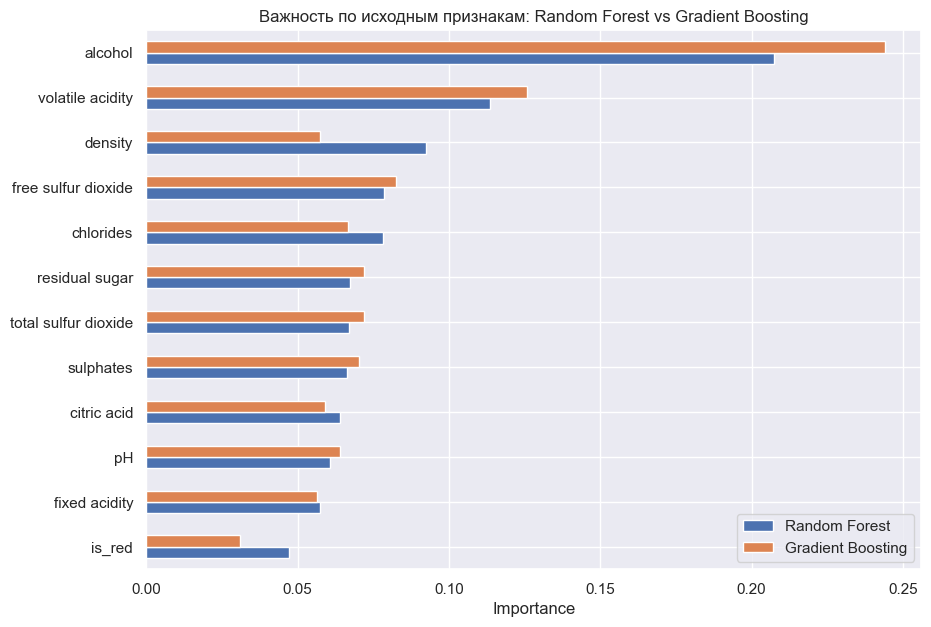

In [38]:
gb_terms = pd.Series(gb_model.named_steps["model"].feature_importances_, index=term_names(gb_model)).sort_values(ascending=False)
gb_importances = importance_by_feature(gb_model)

importances = pd.DataFrame({"Random Forest": rf_importances, "Gradient Boosting": gb_importances}).sort_values("Random Forest")
importances.plot(kind="barh", figsize=(10, 7))
plt.title("Важность по исходным признакам: Random Forest vs Gradient Boosting")
plt.xlabel("Importance")
plt.legend(loc="lower right")

pd.DataFrame({"Random Forest": rf_terms.head(10).index, "Gradient Boosting": gb_terms.head(10).index})

Выводы (сравнение RF и GB):
- По исходным признакам у обеих моделей одинаковый топ-2: `alcohol` (0.24 у бустинга, 0.21 у леса) и `volatile acidity` (0.13 и 0.11). Дальше у бустинга идёт `free sulfur dioxide`, а у леса — `density`.
- `density` у бустинга заметно менее важна (0.06 против 0.09). Объяснение то же, что раньше: плотность в основном дублирует алкоголь. В лесу на каждом разбиении доступна только часть признаков (`max_features=0.3`), и когда алкоголя в этом подмножестве нет, дерево берёт его «заместителя». В бустинге доступны все признаки, и каждое следующее дерево исправляет остатки предыдущих, так что информацию об алкоголе уже забрали первые деревья.
- **Главное отличие — какие новые признаки используются.** В топ-10 у леса в основном исходные признаки и произведения с алкоголем, а у бустинга — почти одни произведения: `volatile acidity × alcohol`, `total sulfur dioxide × sulphates`, `free sulfur dioxide × sulphates`, `free sulfur dioxide × density`, `residual sugar × alcohol`. Бустинг последовательно исправляет ошибки, и после главных эффектов (алкоголь, летучая кислотность) остатки лучше всего объясняются взаимодействиями — поэтому новые признаки ему полезнее, чем лесу.
- Обе модели согласны с EDA в главном: алкоголь и летучая кислотность — самые важные признаки.

# Часть 10. Честное сравнение моделей

Условия для всех моделей одинаковые:
- одни и те же данные: train и test получены одним разбиением в части 2;
- **одни и те же признаки**: все три модели получают на вход одни и те же 90 признаков из части 4 (логарифмы скошенных признаков, масштабирование, квадраты и попарные произведения). Преобразования стоят внутри `Pipeline` каждой модели и обучаются только на train;
- гиперпараметры всех моделей подобраны случайным поиском на одних и тех же фолдах `cv`;
- все метрики посчитаны на одном и том же test.

Единственное отличие — у `Ridge` после полиномиальных признаков стоит ещё один `StandardScaler`: регуляризация штрафует все веса одинаково, поэтому признаки для неё должны быть в одном масштабе. Деревьям масштаб не важен.

In [39]:
results_df = pd.DataFrame(results).T
results_df["Лучше baseline"] = results_df["RMSE"] < results_df.loc["Baseline", "RMSE"]
results_df["RMSE < 0.70"] = results_df["RMSE"] < 0.70
results_df.round(4)

,RMSE,MAE,CV RMSE,Лучше baseline,RMSE < 0.70
Baseline,0.8738,0.6861,0.8732,False,False
Linear Regression (Ridge),0.6945,0.5421,0.7026,True,True
Random Forest,0.5976,0.4340,0.6185,True,True
Gradient Boosting,0.5852,0.3981,0.6089,True,True


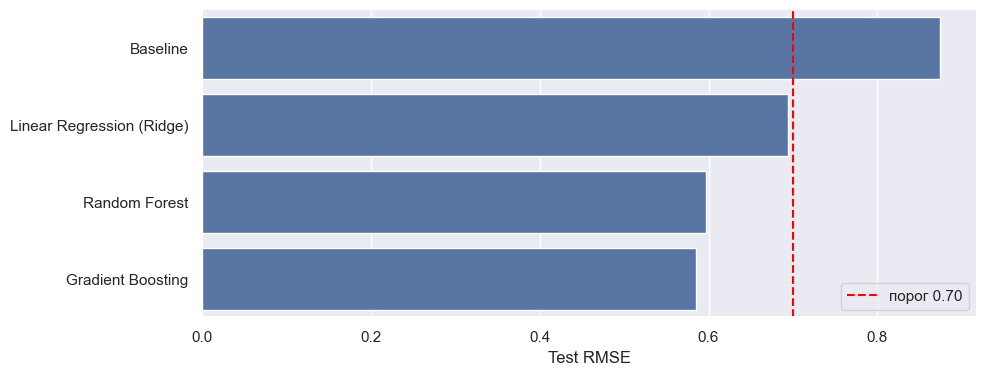

In [40]:
plot = sns.barplot(y=results_df.index, x=results_df["RMSE"], color="C0")
plot.figure.set_size_inches(10, 4)
plt.axvline(0.70, color="red", linestyle="--", label="порог 0.70")
plt.xlabel("Test RMSE")
plt.ylabel("")
plt.legend()

Выводы:
- **Все три модели превзошли baseline** (0.874): линейная модель — на 21% (0.695), случайный лес — на 32% (0.598), бустинг — на 33% (0.585). Т.е. модели действительно извлекают информацию из признаков, а не просто выдают среднее.
- **Порог 0.70 на тесте проходят все три модели.** Но у линейной модели запас минимальный: по CV она на границе (0.703).
- Порядок моделей по CV и по тесту одинаковый (бустинг → лес → линейная модель), и CV близок к тестовому. Значит, выбор по кросс-валидации работает, и тест не «подогнан».

Почему так получилось:
- **Новые признаки больше всего помогли линейной модели**: на исходных признаках у неё было CV 0.738, на новых — 0.703. Её главной проблемой было недообучение (она не умела описывать изгибы и разные наклоны для типов вина), и полиномиальные признаки как раз это добавили.
- **Деревьям новые признаки помогают меньше**: лес и бустинг и сами находят нелинейности и взаимодействия через последовательность разбиений. Готовые произведения им лишь немного упрощают задачу (особенно бустингу, который в топе важностей использует в основном произведения).
- **Деревья всё равно точнее линейной модели.** Во-первых, линейная модель даже с полиномами 2-й степени умеет описывать только плавные изгибы и попарные взаимодействия, а деревья — любые пороги и взаимодействия любой сложности. Во-вторых, деревья умеют «запоминать» конкретные объекты, а в данных много повторов: в части 12 видно, что заметная часть их преимущества приходится именно на вина с копией в train.
- **Бустинг чуть лучше леса** (0.609 против 0.619 на CV), но разница сравнима с разбросом по фолдам (≈0.013), так что считать её значимой нельзя.
- **MAE у всех моделей заметно меньше RMSE** (у бустинга 0.398 против 0.585): большинство вин предсказывается точно, а RMSE раздувают редкие крупные ошибки. Это разберу в анализе ошибок.

# Часть 11. Feature importance: сравнение моделей

Сравнивать напрямую веса линейной модели и `feature_importances_` деревьев некорректно — это разные величины. К тому же impurity-based importance у деревьев считается по train и завышает важность признаков с большим числом уникальных значений, а у моделей на полиномиальных признаках важность к тому же «размазана» по квадратам и произведениям.

Поэтому для всех трёх моделей дополнительно посчитаю **permutation importance по исходным 12 признакам**: случайно перемешиваю значения одного исходного признака в тестовой выборке (а значит, и все квадраты и произведения, которые из него строятся внутри пайплайна) и смотрю, насколько вырастет RMSE. Это одна и та же величина (прирост RMSE в баллах) для любой модели, поэтому модели можно сравнивать между собой. Считаю на тесте, потому что модели уже обучены и зафиксированы, и по этим результатам ничего не выбирается — это только интерпретация.

Text(0.5, 0, 'Прирост RMSE')

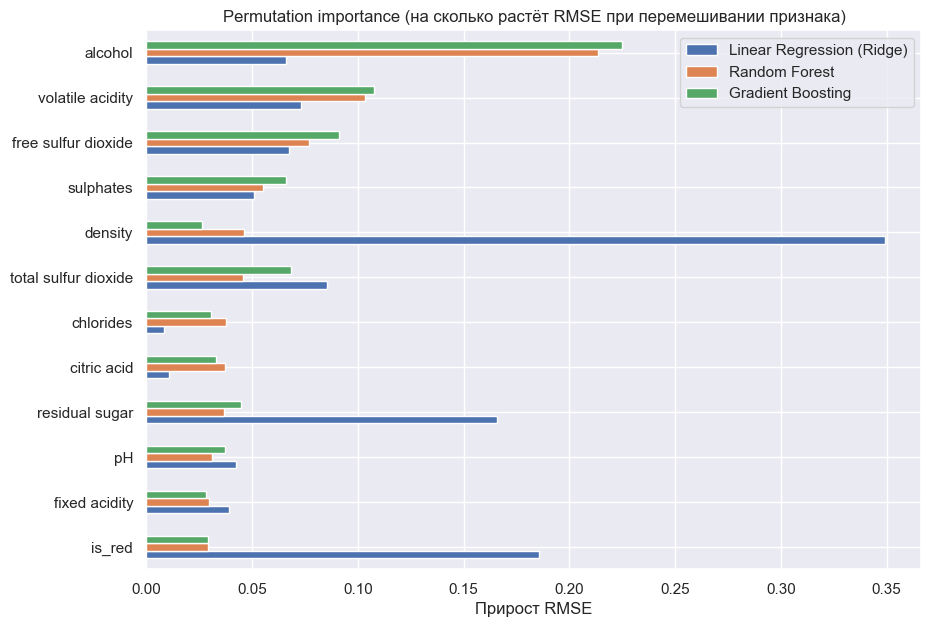

In [41]:
from sklearn.inspection import permutation_importance

models = {"Linear Regression (Ridge)": linear_fe, "Random Forest": rf_model, "Gradient Boosting": gb_model}

perm_importances = {}
for name, model in models.items():
    perm = permutation_importance(model, X_test, y_test, scoring="neg_root_mean_squared_error", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    perm_importances[name] = pd.Series(perm.importances_mean, index=X_test.columns)

perm_importances = pd.DataFrame(perm_importances).sort_values("Random Forest")
perm_importances.plot(kind="barh", figsize=(10, 7))
plt.title("Permutation importance (на сколько растёт RMSE при перемешивании признака)")
plt.xlabel("Прирост RMSE")

In [42]:
ranks = pd.DataFrame({
    "|corr| с quality": X_train.corrwith(y_train).abs(),
    "|вес| LR (исходные)": coefs["|вес после масштабирования|"],
    "RF importance": rf_importances,
    "GB importance": gb_importances,
    "perm Ridge": perm_importances["Linear Regression (Ridge)"],
    "perm RF": perm_importances["Random Forest"],
    "perm GB": perm_importances["Gradient Boosting"],
}).rank(ascending=False).astype(int)
ranks.sort_values("perm RF")

,|corr| с quality,|вес| LR (исходные),RF importance,GB importance,perm Ridge,perm RF,perm GB
alcohol,1,3,1,1,7,1,1
volatile acidity,3,4,2,2,5,2,2
free sulfur dioxide,8,10,4,3,6,3,3
sulphates,11,7,8,6,8,4,5
density,2,1,3,10,1,5,12
total sulfur dioxide,9,8,7,4,4,6,4
chlorides,4,11,5,7,12,7,9
citric acid,7,12,9,9,11,8,8
residual sugar,10,2,6,5,3,9,6
pH,12,9,10,8,9,10,7


Выводы:
- **Модели на деревьях согласны между собой**: у леса и бустинга по permutation importance одинаковый топ-3 — `alcohol` (перемешивание увеличивает RMSE на ~0.21–0.23), `volatile acidity` (~0.10) и `free sulfur dioxide` (~0.08–0.09), дальше `sulphates` и `total sulfur dioxide`.
- **Линейная модель опирается на совсем другое**: самые важные для неё `density` (+0.35 к RMSE при перемешивании!), `is_red` (+0.19) и `residual sugar` (+0.17), а `alcohol` всего +0.07. Причина в том, как устроена модель на полиномиальных признаках: плотность входит в 13 из 90 признаков (`density`, `density²` и 11 произведений вроде `density × is_red`, `residual sugar × density`), и через неё модель фактически описывает алкоголь и сахар (плотность ≈ функция от них). Если перемешать плотность, ломаются сразу все эти слагаемые. Похожая история с `is_red`: на нём построены 11 произведений «разные наклоны для типов вина», и без него модель теряет всю разницу между красным и белым. Деревьям же `is_red` почти не нужен — тип вина они восстанавливают по другим признакам.
- **`free sulfur dioxide`** важен для всех моделей (3-е место у деревьев, 6-е у линейной), хотя в EDA его линейная корреляция с качеством около нуля (0.06). Его связь с качеством нелинейная — у линейной модели это видно по отрицательному весу `free sulfur dioxide²` (перевёрнутая «U»: плохо и мало, и много).
- **Сопоставление с EDA**: признаки с самой сильной корреляцией (алкоголь, летучая кислотность) — главные для деревьев. `density` и `chlorides`, которые по корреляции были на 2-м и 4-м местах, для деревьев второстепенные: их связь с качеством идёт в основном «через» алкоголь и тип вина. У линейной модели наоборот, плотность главная — но это особенность того, как модель распределила веса между скоррелированными признаками, а не отдельный «эффект плотности».

**Можно ли на основании feature importance утверждать, что изменение признака является причиной изменения качества вина?**

Нет. Feature importance показывает только то, насколько **модель** использует признак для предсказания, т.е. насколько он статистически связан с оценкой в этих данных. Причинность из этого не следует:
1. **Данные наблюдательные**, а не экспериментальные: никто не менял один признак при фиксированных остальных. Мы видим только, что крепкие вина в среднем получают более высокие оценки.
2. **Есть скрытые общие причины (конфаундеры)**: сорт винограда, погода, зрелость ягод, технология производства влияют одновременно и на химический состав, и на качество. Например, высокий алкоголь — признак спелого винограда и правильного брожения. Если в плохое вино просто долить спирт, лучше оно не станет.
3. **Скоррелированные признаки подменяют друг друга**: это очень хорошо видно здесь — для линейной модели главный признак плотность, для деревьев алкоголь, хотя речь об одной и той же информации. Важность признака зависит от того, какие ещё признаки есть в модели и как модель распределила между ними веса.
4. **Важность зависит от модели и способа подсчёта**: MDI и permutation importance, линейная модель и деревья дают разные рейтинги на одних и тех же данных. Настоящий причинный эффект от выбора модели не зависел бы.
5. Важность ничего не говорит о **направлении** влияния и о том, при каких значениях признак работает (например, у свободного SO₂ «хорошо» — где-то посередине).

Чтобы говорить о причинности, нужен эксперимент (например, менять один параметр при производстве и сравнивать слепые оценки) или специальные методы причинного вывода с явными предположениями.

# Часть 12. Анализ ошибок лучшей модели

Лучшую модель выбираю по CV RMSE (а не по тесту).

In [43]:
best_name = results_df.drop(index="Baseline")["CV RMSE"].astype(float).idxmin()
best_model = models[best_name]
print("Лучшая модель по CV:", best_name)

errors = pd.DataFrame({"true": y_test, "pred": best_model.predict(X_test)})
errors["error"] = errors["pred"] - errors["true"]
errors["abs_error"] = errors["error"].abs()

print("Средняя ошибка (смещение) = %.4f" % errors["error"].mean())
print("Доля объектов с |ошибкой| < 0.5: %.3f" % (errors["abs_error"] < 0.5).mean())
print("Доля объектов с |ошибкой| > 1: %.3f" % (errors["abs_error"] > 1).mean())
print("Доля объектов с |ошибкой| > 2: %.3f" % (errors["abs_error"] > 2).mean())

Лучшая модель по CV: Gradient Boosting
Средняя ошибка (смещение) = 0.0402
Доля объектов с |ошибкой| < 0.5: 0.696
Доля объектов с |ошибкой| > 1: 0.093
Доля объектов с |ошибкой| > 2: 0.012


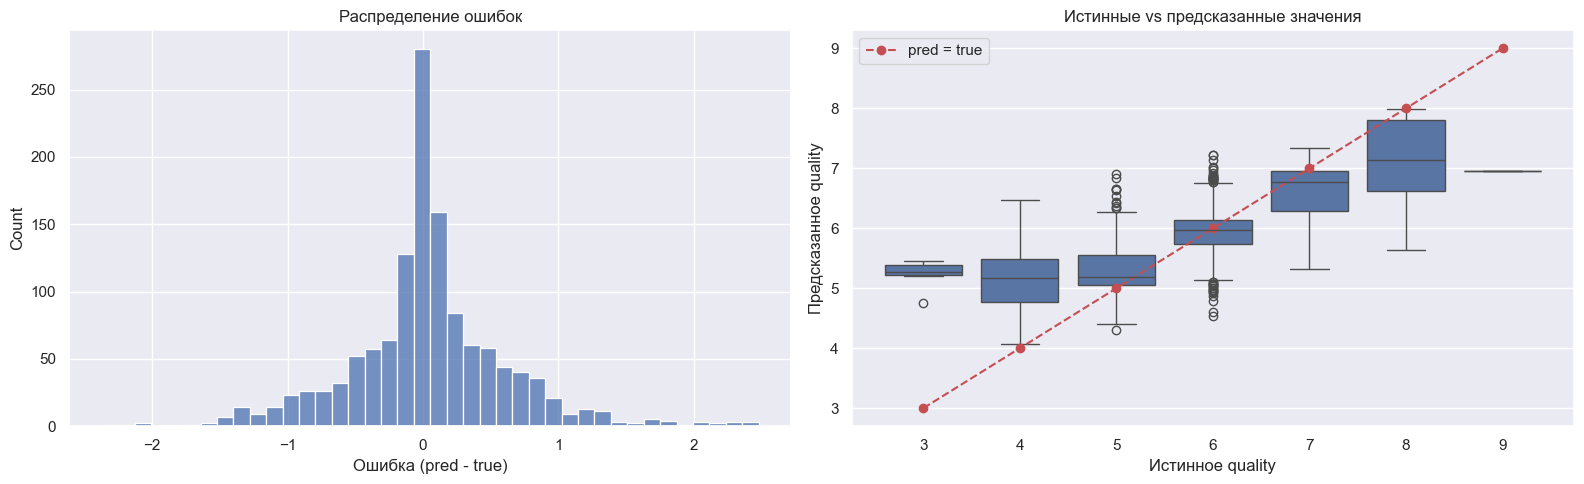

In [44]:
qualities = sorted(errors["true"].unique())

fig, axs = plt.subplots(figsize=(16, 5), ncols=2)
sns.histplot(errors["error"], bins=40, ax=axs[0])
axs[0].set_xlabel("Ошибка (pred - true)")
axs[0].set_title("Распределение ошибок")

sns.boxplot(data=errors, x="true", y="pred", color="C0", ax=axs[1])
axs[1].plot(range(len(qualities)), qualities, "r--o", label="pred = true")
axs[1].set_xlabel("Истинное quality")
axs[1].set_ylabel("Предсказанное quality")
axs[1].set_title("Истинные vs предсказанные значения")
axs[1].legend()
plt.tight_layout()

In [45]:
by_quality = errors.groupby("true").agg(
    count=("error", "size"),
    mean_pred=("pred", "mean"),
    mean_error=("error", "mean"),
    MAE=("abs_error", "mean"),
    RMSE=("error", lambda e: np.sqrt(np.mean(e ** 2))),
)
by_quality.round(3)

,count,mean_pred,mean_error,MAE,RMSE
true,,,,,
3,6,5.228,2.228,2.228,2.240
4,43,5.185,1.185,1.185,1.326
5,428,5.326,0.326,0.358,0.512
6,567,5.951,-0.049,0.303,0.416
7,216,6.596,-0.404,0.427,0.603
8,39,7.124,-0.876,0.876,1.088
9,1,6.961,-2.039,2.039,2.039


Выводы (лучшая модель по CV — бустинг):
- Ошибки распределены примерно симметрично вокруг нуля, смещения почти нет (средняя ошибка 0.04). У 70% вин ошибка меньше полбалла, т.е. после округления они получили бы правильную оценку. Ошибка больше 1 балла — у 9% вин, больше 2 баллов — у 1%.
- Но для разных оценок модель работает **неодинаково**. Для самых частых оценок 5 и 6 ошибка небольшая (RMSE 0.51 и 0.42), а дальше от центра она быстро растёт: для 4 и 8 RMSE уже 1.33 и 1.09, для 3 и 9 — больше 2.
- Видна **систематическая «тяга к центру»**: плохие вина модель переоценивает (для оценки 3 предсказывает в среднем 5.23, для 4 — 5.19), а хорошие недооценивает (для 8 в среднем 7.12, для 9 — 6.96). На графике справа медианы предсказаний лежат на более пологой линии, чем идеальная диагональ.
- Именно поэтому RMSE (0.585) настолько больше MAE (0.398): крупные ошибки сосредоточены на немногочисленных крайних винах.

**Почему модель хуже предсказывает редкие значения quality:**
1. **Мало примеров.** Вин с оценкой 3 в train около 24, с оценкой 9 — 4, а с оценками 5–6 почти 4000. Модель минимизирует среднюю ошибку по всем объектам, и ей выгоднее хорошо предсказывать массовые вина, чем подстраиваться под единичные.
2. **Деревья усредняют.** Предсказание дерева — среднее таргета в листе. Редкое вино попадает в лист вместе с похожими по химии винами, у которых оценки 5–6, и среднее сдвигается к центру.
3. **Плохие и отличные вина часто химически не отличаются от средних.** Оценка — субъективное мнение экспертов, в ней есть шум, а часть того, что влияет на оценку (аромат, вкус, баланс), в 11 измерениях не отражена.
4. **Регрессия с MSE в принципе тянет к условному среднему**: если по признакам вино похоже и на «пятёрку», и на «тройку», то оптимальный с точки зрения MSE ответ — где-то посередине, ближе к более частой оценке.

In [46]:
worst = errors.sort_values("abs_error", ascending=False).head(10)
X_test.loc[worst.index].join(worst[["true", "pred", "error"]]).round(3)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red,true,pred,error
6107,5.8,0.260,0.30,2.60,0.034,75.0,129.0,0.990,3.20,0.38,11.5,0,4,6.479,2.479
3287,6.7,0.250,0.26,1.55,0.041,118.5,216.0,0.995,3.55,0.63,9.4,0,3,5.460,2.460
2339,6.9,0.390,0.40,4.60,0.022,5.0,19.0,0.992,3.31,0.37,12.6,0,3,5.415,2.415
3005,8.2,0.220,0.36,6.80,0.034,12.0,90.0,0.994,3.01,0.38,10.5,0,8,5.629,-2.371
5369,7.4,0.270,0.31,2.40,0.014,15.0,143.0,0.991,3.03,0.65,12.0,0,4,6.336,2.336
1374,6.8,0.815,0.00,1.20,0.267,16.0,29.0,0.995,3.32,0.51,9.8,1,3,5.281,2.281
1850,8.5,0.260,0.21,16.20,0.074,41.0,197.0,0.998,3.02,0.50,9.8,0,3,5.251,2.251
1469,7.3,0.980,0.05,2.10,0.061,20.0,49.0,0.997,3.31,0.55,9.7,1,3,5.211,2.211
1403,7.2,0.330,0.33,1.70,0.061,3.0,13.0,0.996,3.23,1.10,10.0,1,8,5.841,-2.159
3715,6.8,0.200,0.27,1.20,0.034,19.0,68.0,0.990,3.14,0.37,11.7,0,4,6.121,2.121


In [47]:
# типичные значения ключевых признаков для каждой оценки (по train), чтобы было с чем сравнивать
train.groupby(["is_red", "quality"])[["alcohol", "volatile acidity", "density", "sulphates", "chlorides", "free sulfur dioxide"]].median().round(3)

alcohol  volatile acidity  density  sulphates  chlorides  \
is_red quality                                                             
0      3         10.500             0.260    0.994      0.435      0.041   
       4         10.000             0.330    0.994      0.470      0.047   
       5          9.500             0.280    0.995      0.470      0.047   
       6         10.400             0.250    0.994      0.480      0.043   
       7         11.350             0.250    0.992      0.480      0.037   
       8         11.900             0.250    0.992      0.460      0.036   
       9         12.550             0.315    0.990      0.440      0.027   
1      3         10.075             0.818    0.998      0.555      0.090   
       4         10.400             0.670    0.996      0.560      0.076   
       5          9.700             0.580    0.997      0.580      0.081   
       6         10.500             0.495    0.997      0.640      0.078   
       7         11.600             0.370    0.996      0.730      0.073   
       8         11.700             0.360    0.995      0.740      0.070   

                free sulfur dioxide  
is_red quality                       
0      3                       33.5  
       4                       18.0  
       5                       35.0  
       6                       34.0  
       7                       33.0  
       8                       35.0  
       9                       29.5  
1      3                        5.5  
       4                       11.0  
       5                       15.0  
       6                       14.0  
       7                       11.0  
       8                       15.0

Разберу несколько вин с самыми большими ошибками (сравниваю с медианами признаков для их типа и оценки в таблице выше):
- **№3005** (белое, реальная оценка 8, предсказано 5.63). Алкоголь 10.5 — уровень вин на 5–6 (у белых с оценкой 8 медиана 11.9), сульфаты 0.38 ниже типичного, свободного SO₂ мало (12 при медиане 35). По признакам, которые модель считает главными, это обычное среднее вино. Скорее всего, его качество определяется тем, чего нет в данных (аромат, вкус), или это шум в оценке.
- **№6107** и **№5369** (белые, оценка 4, предсказано 6.48 и 6.34) — обратная ситуация. Алкоголь 11.5 и 12.0, как у хороших вин, летучая кислотность обычная (0.26–0.27). У этих вин нет ни одного из «дефектов», которые модель умеет распознавать, поэтому она ставит им хорошую оценку.
- **№3287** (белое, оценка 3, предсказано 5.46): очень много диоксида серы — свободного 118.5 и общего 216 (у белых вин медиана свободного около 34). Сильный запах серы — известный дефект вина, и модель это частично учла: предсказание ниже среднего. Но до 3 не дотянула — таких вин в train единицы.
- **№2339** (белое, оценка 3, предсказано 5.42): наоборот, диоксида серы очень мало (свободного 5, общего 19 — для белого вина это крайне низко), при этом алкоголь высокий (12.6). Высокий алкоголь тянет предсказание вверх, а нехватка SO₂ (плохая защита от окисления) — вниз, и модель остановилась посередине.
- **№1374** и **№1469** (красные, оценка 3, предсказано ~5.2–5.3): здесь модель правильно увидела проблему — очень высокая летучая кислотность (0.815 и 0.98, у красных с оценкой 5 медиана 0.58), у №1374 ещё и очень много хлоридов (0.267). Предсказание ниже среднего, но до 3 модель не дотягивает: красных вин с оценкой 3 в train всего несколько, и в листьях деревьев они усредняются с винами на 5.
- **№1403** (красное, оценка 8, предсказано 5.84): алкоголь 10.0 (у красных с оценкой 8 медиана 11.7) и необычный состав — очень много сульфатов (1.10) и почти нет SO₂ (свободного 3, общего 13). По главному признаку — алкоголю — это среднее вино, и модель не видит, за что ему поставили 8.

Общая картина: крупные ошибки — это либо редкие крайние оценки, до которых модель «не дотягивается» из-за усреднения, либо вина, у которых химический профиль типичен для другой оценки (тогда причина вне признаков или в субъективности оценки).

Отдельно проверю, насколько на оценку влияют повторы, найденные в начале: посчитаю ошибку отдельно для тестовых вин, у которых есть точная копия (по признакам) в train, и для остальных. Для сравнения — для всех трёх моделей.

In [48]:
train_rows = set(map(tuple, X_train.values))
has_copy = np.array([tuple(row) in train_rows for row in X_test.values])
print("Доля тестовых вин, у которых есть копия в train: %.3f" % has_copy.mean())

copy_check = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    copy_check[name] = {
        "RMSE (весь test)": root_mean_squared_error(y_test, y_pred),
        "RMSE (есть копия в train)": root_mean_squared_error(y_test[has_copy], y_pred[has_copy]) if has_copy.sum() > 0 else np.nan,
        "RMSE (нет копии в train)": root_mean_squared_error(y_test[~has_copy], y_pred[~has_copy]),
    }
pd.DataFrame(copy_check).T.round(4)

Доля тестовых вин, у которых есть копия в train: 0.275


,RMSE (весь test),RMSE (есть копия в train),RMSE (нет копии в train)
Linear Regression (Ridge),0.6945,0.6751,0.7018
Random Forest,0.5976,0.2652,0.6824
Gradient Boosting,0.5852,0.0907,0.6849


Это важный результат:
- У 27.5% тестовых вин есть точная копия в train (это те самые дубликаты из части 1).
- На таких винах лес и бустинг почти не ошибаются: у леса RMSE 0.27, а у бустинга вообще 0.09 — он фактически вспоминает оценку копии (на train у него RMSE 0.08). Линейная модель запоминать не умеет, и у неё разница между копиями и остальными винами небольшая (0.68 против 0.70).
- На винах **без копии** в train RMSE у леса и бустинга почти одинаковый: 0.682 и 0.685. Это честная оценка качества на действительно новых винах — порог 0.70 они проходят, но с небольшим запасом. У линейной модели на новых винах 0.702, т.е. ровно на пороге.
- Получается, что разница между бустингом и лесом в итоговой таблице почти целиком набирается на копиях: бустинг лучше «запоминает» повторы, а на новых винах модели одинаковые. А разрыв между деревьями и линейной моделью на новых винах — около 0.02, а не 0.1, как в общей таблице.

Итого: общий тестовый RMSE корректен для выборки, устроенной как исходный датасет (с повторами), но для новых, ранее не встречавшихся вин надо ориентироваться на ~0.68 у деревьев и ~0.70 у линейной модели. Это же объясняет, почему подбор гиперпараметров выбрал очень глубокие деревья и маленькие листья: в кросс-валидации повторы тоже попадают в разные фолды, и запоминать выгодно. Если запустить ноутбук без дубликатов (строка в части 1), этого эффекта не будет, и качество будет ближе к последней колонке.

# Итоги

| Модель | RMSE | MAE | CV RMSE |
|---|---|---|---|
| Baseline (среднее по train) | 0.874 | 0.686 | 0.873 |
| Linear Regression (Ridge, новые признаки) | 0.695 | 0.542 | 0.703 |
| Random Forest | 0.598 | 0.434 | 0.619 |
| Gradient Boosting | 0.585 | 0.398 | 0.609 |

- Красное и белое вино объединены в одну таблицу, тип закодирован признаком `is_red`. Разбиение 80/20 со стратификацией по `quality`, `random_state=42`. Все решения приняты по 5-fold CV на train, гиперпараметры подобраны случайным поиском (`RandomizedSearchCV`), тест использован только для финальной оценки.
- Все модели обучены на **одинаковых признаках**: логарифм скошенных признаков, масштабирование, квадраты и попарные произведения — 90 признаков из 12. Набор выбран по кросс-валидации: он лучше и исходных признаков, и «набора из EDA» (только квадраты и произведения с `is_red`).
- Новые признаки сильнее всего помогли линейной модели: CV RMSE 0.738 → 0.703, на тесте она теперь проходит порог. Деревьям они помогают меньше — нелинейности и взаимодействия они находят и сами.
- Все модели лучше baseline и проходят порог RMSE < 0.70 на тесте. Лучшая модель — Gradient Boosting (RMSE = 0.585, MAE = 0.398).
- Самые важные признаки для деревьев — `alcohol` и `volatile acidity`, что совпадает с EDA; линейная модель распределяет ту же информацию через `density` и произведения с `is_red`. Важность признаков не означает причинную связь.
- Хуже всего модели предсказывают редкие оценки (3–4 и 8–9) и тянут предсказания к центру.
- У ~27% тестовых вин есть копия в train, и на них деревья почти не ошибаются. На новых винах честный RMSE ≈ 0.68 у деревьев и ≈ 0.70 у линейной модели.